# Assignment 12 --- Progressive Growing GAN (ProGAN)

**Md. Shoaib Abdullah Khan · ID: 2010976135**

This notebook implements a **Progressive Growing GAN** (Karras *et al.*, ICLR 2018) from scratch in
PyTorch and trains it on **one class of CIFAR-10 (`horse`)**, growing the image resolution
**32 × 32 → 64 × 64 → 128 × 128**.

| Assignment task | Where it is done |
|---|---|
| Select a favourite CIFAR-10 class and prepare its training images | §1 |
| Implement ProGAN | §2 (building blocks, Generator, Discriminator, fade-in) |
| Train while progressively increasing resolution 32 → 64 → 128 | §4 (training) and §5 (training dynamics) |
| Generate and save synthetic images at each resolution | §6 (`outputs/generated/{032,064,128}`) |
| Evaluate by visual inspection **and** quantitative metrics | §6 (visual), §7 (FID, KID, precision/recall, classifier), §8 (memorisation, spectra, interpolation) |
| Document architecture, training procedure, results, challenges | §2, §4, §7–§9, §10 |

### Design in one paragraph

ProGAN starts from a 4 × 4 generator/discriminator pair and adds one resolution block at a time.
Every new block is **faded in** linearly: for a while the output is a blend of the old
(upsampled) image and the new block's image, so the networks never have to cope with a sudden
architectural change. The assignment's three resolutions (32, 64, 128) are the last three
stages; the 4 → 8 → 16 stages are the standard ProGAN warm-up that lays down coarse shape and
colour before any fine detail is learned. All of the paper's stabilisation tricks are
implemented: **equalised learning rate**, **pixel-wise feature normalisation**, the
**minibatch standard-deviation layer**, the **WGAN-GP** loss with the small **drift** term, and an
**exponential moving average (EMA)** of the generator weights for sampling.

> **An important fact about the data.** CIFAR-10 images are *natively* 32 × 32. There are no
> real 64 × 64 or 128 × 128 horse photographs in the dataset, so the "real" images at those
> resolutions are 32 × 32 images upsampled with bicubic interpolation (§1.3). This shapes what
> the 64 and 128 stages can learn and is analysed explicitly in §7.3 and §8.3.

## 0. Environment

Only `torch-fidelity` (Inception-v3 feature extractor used by FID / KID) is non-standard. The
install line is commented out because the environment already has it.

In [1]:
# %pip install -q torch torchvision torch-fidelity numpy scipy pandas matplotlib pillow

## 1. Imports, configuration and reproducibility

All hyper-parameters live in one `Config` object so the progressive run and the
non-progressive ablation (§9) are guaranteed to share every setting except the one being
tested.

In [2]:
import os, sys, json, time, math, copy, pickle, random, warnings
from pathlib import Path
from dataclasses import dataclass, asdict, field

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from scipy import linalg

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------- paths
ROOT  = Path.cwd()                                   # .../Assignments/12
CIFAR = ROOT.parent / "01" / "data" / "cifar-10-batches-py"
DATA  = ROOT / "data"
OUT   = ROOT / "outputs"
FIG   = OUT / "figures"
RES   = OUT / "results"
CKPT  = OUT / "checkpoints"
GEN   = OUT / "generated"
for d in (DATA, FIG, RES, CKPT, GEN):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------- config
@dataclass
class Config:
    class_name: str  = "horse"
    z_dim: int       = 256
    # feature maps per resolution             4    8   16   32   64  128
    chans: tuple     = (256, 256, 256, 256, 128, 64)
    batch: int       = 64
    lr: float        = 1e-3          # ProGAN: Adam(lr=1e-3, beta1=0, beta2=0.99, eps=1e-8)
    betas: tuple     = (0.0, 0.99)
    gp_lambda: float = 10.0          # WGAN-GP weight
    gp_every: int    = 4             # lazy gradient penalty (see §4.1)
    gp_batch: int    = 32            # samples used for the penalty
    drift: float     = 1e-3          # epsilon_drift * E[D(x)^2]
    ema_beta: float  = 0.999         # generator weight averaging
    amp: bool        = True          # bfloat16 autocast
    # kimg (thousands of real images shown) per stage: (fade-in, stabilise)
    schedule: dict   = field(default_factory=lambda: {
        4: (0, 120), 8: (120, 120), 16: (120, 120),
        32: (200, 400), 64: (150, 250), 128: (150, 250)})
    fid_every_kimg: int = 50         # quick FID cadence during training (res >= 16)
    fid_quick_n: int    = 2000
    snap_every_kimg: int = 20
    eval_n: int         = 5000       # samples for the final FID / KID / P-R
    seed: int           = 12

CFG = Config()
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = False   # see §10: autotuning stalls on the GP double-backward

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

print("torch", torch.__version__, "| device:", DEV,
      torch.cuda.get_device_name(0) if DEV.type == "cuda" else "")
print(json.dumps({k: (str(v) if isinstance(v, (dict, tuple)) else v)
                  for k, v in asdict(CFG).items()}, indent=1))

torch 2.7.1+cu128 | device: cuda NVIDIA GeForce RTX 5070 Ti
{
 "class_name": "horse",
 "z_dim": 256,
 "chans": "(256, 256, 256, 256, 128, 64)",
 "batch": 64,
 "lr": 0.001,
 "betas": "(0.0, 0.99)",
 "gp_lambda": 10.0,
 "gp_every": 4,
 "gp_batch": 32,
 "drift": 0.001,
 "ema_beta": 0.999,
 "amp": true,
 "schedule": "{4: (0, 120), 8: (120, 120), 16: (120, 120), 32: (200, 400), 64: (150, 250), 128: (150, 250)}",
 "fid_every_kimg": 50,
 "fid_quick_n": 2000,
 "snap_every_kimg": 20,
 "eval_n": 5000,
 "seed": 12
}


In [3]:
# ---------------------------------------------------------------- plotting style
# Categorical palette in a FIXED slot order; a resolution keeps the same colour in every figure.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8984"
SURFACE, GRIDC  = "#ffffff", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "lines.linewidth": 1.8, "figure.max_open_warning": 0,
})
RES_COLOR = {4: PALETTE[6], 8: PALETTE[4], 16: PALETTE[3], 32: PALETTE[0], 64: PALETTE[1], 128: PALETTE[2]}
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seqblue", ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

def savefig(fig, name):
    fig.savefig(FIG / name)
    print("saved ->", (FIG / name).relative_to(ROOT))

def to_uint8(x):
    # [-1,1] float NCHW -> uint8 NCHW (CPU)
    return ((x.float().clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8).cpu()

def grid_image(imgs_u8, nrow, pad=2, upscale_to=None):
    # uint8 NCHW -> HWC numpy grid (optionally nearest-upscaled so small images stay crisp)
    x = imgs_u8
    if upscale_to is not None and x.shape[-1] != upscale_to:
        x = F.interpolate(x.float(), size=upscale_to, mode="nearest").to(torch.uint8)
    g = torchvision.utils.make_grid(x, nrow=nrow, padding=pad, pad_value=255)
    return g.permute(1, 2, 0).numpy()

def stage_spans(ax, phases, text=True, ymax_frac=0.98):
    # shades each resolution stage; light hatch for the fade-in part
    for p in phases:
        c = RES_COLOR[p["res"]]
        ax.axvspan(p["k0"], p["k1"], color=c, alpha=0.06 if p["phase"] == "stab" else 0.14, lw=0)
        if text and p["phase"] == "stab":
            ax.text((p["k0"] + p["k1"]) / 2, ymax_frac, f'{p["res"]}²', transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=7.5, color=c, fontweight="bold")

---
# 1. Data: choosing a class and preparing the training images

## 1.1 Loading CIFAR-10 and selecting the class

CIFAR-10 (Krizhevsky, 2009) has 60 000 colour images of 32 × 32 pixels in ten classes, 6 000 per
class (5 000 train / 1 000 test). The local copy from Assignment 1 is reused; if it is missing it
is downloaded with `torchvision`.

**Chosen class: `horse`.** Horses are a good test for a GAN: they have a strong, recognisable
global structure (four legs, long neck, head) that a generator must get right, but also a large
intra-class variety (brown/white/black coats, riders, side and frontal views, grass or sand or
show-jumping backgrounds). A model that only captures colour statistics will visibly fail on
the shape, which makes visual inspection informative.

Only the **5 000 training horses** are used to train the GAN. The **1 000 test horses** are
never shown to it; they serve as an independent real sample that tells us what FID/KID a
*perfect* generator would get with the same sample size (§7.1) and as a reference for the
memorisation test (§8.1).

In [4]:
def load_cifar(root):
    if not root.exists():
        torchvision.datasets.CIFAR10(DATA, train=True, download=True)
        root = DATA / "cifar-10-batches-py"
    def read(f):
        with open(root / f, "rb") as fh:
            d = pickle.load(fh, encoding="bytes")
        return d[b"data"].reshape(-1, 3, 32, 32), np.array(d[b"labels"])
    tr = [read(f"data_batch_{i}") for i in range(1, 6)]
    Xtr, ytr = np.concatenate([a for a, _ in tr]), np.concatenate([b for _, b in tr])
    Xte, yte = read("test_batch")
    with open(root / "batches.meta", "rb") as fh:
        names = [n.decode() for n in pickle.load(fh, encoding="bytes")[b"label_names"]]
    return Xtr, ytr, Xte, yte, names

Xtr_all, ytr_all, Xte_all, yte_all, CLASSES = load_cifar(CIFAR)
CLS = CLASSES.index(CFG.class_name)
X_train = Xtr_all[ytr_all == CLS]          # uint8 (5000, 3, 32, 32)
X_test  = Xte_all[yte_all == CLS]          # uint8 (1000, 3, 32, 32)

np.save(DATA / f"{CFG.class_name}_train_32.npy", X_train)
np.save(DATA / f"{CFG.class_name}_test_32.npy",  X_test)

print("CIFAR-10 classes:", CLASSES)
print(f"full train / test       : {len(Xtr_all)} / {len(Xte_all)}")
print(f"selected class          : '{CFG.class_name}' (label {CLS})")
print(f"  training images (GAN) : {X_train.shape}  dtype={X_train.dtype}")
print(f"  held-out test images  : {X_test.shape}")
m = X_train.reshape(len(X_train), 3, -1).mean(axis=(0, 2)); s = X_train.reshape(len(X_train), 3, -1).std(axis=(0, 2))
print(f"  per-channel mean (RGB): {np.round(m, 1)}   std: {np.round(s, 1)}")

CIFAR-10 classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
full train / test       : 50000 / 10000
selected class          : 'horse' (label 7)
  training images (GAN) : (5000, 3, 32, 32)  dtype=uint8
  held-out test images  : (1000, 3, 32, 32)
  per-channel mean (RGB): [128.  122.4 106.3]   std: [62.  62.2 64.2]


saved -> outputs\figures\fig01_real_samples.png


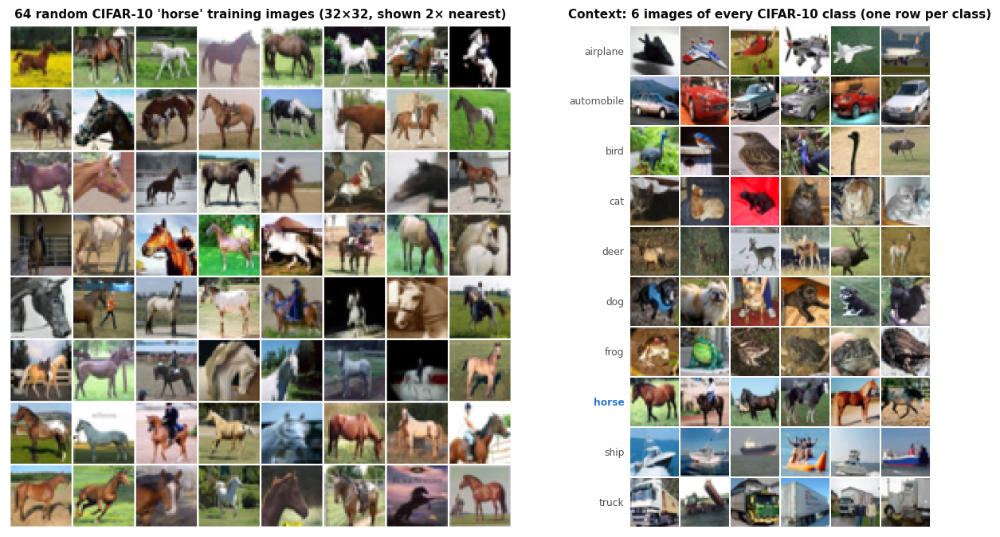

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
rng = np.random.default_rng(0)
idx = rng.choice(len(X_train), 64, replace=False)
axes[0].imshow(grid_image(torch.from_numpy(X_train[idx]), 8, upscale_to=64))
axes[0].set_title(f"64 random CIFAR-10 '{CFG.class_name}' training images (32×32, shown 2× nearest)")
# ten other classes for context
ctx = np.concatenate([Xtr_all[ytr_all == c][:6] for c in range(10)])
axes[1].imshow(grid_image(torch.from_numpy(ctx), 6, upscale_to=64))
axes[1].set_title("Context: 6 images of every CIFAR-10 class (one row per class)")
for i, n in enumerate(CLASSES):
    axes[1].text(-6, 34 + i * 66, n, ha="right", va="center", fontsize=8,
                 color=PALETTE[0] if i == CLS else INK2, fontweight="bold" if i == CLS else None)
for a in axes: a.axis("off")
plt.tight_layout(); savefig(fig, "fig01_real_samples.png"); plt.show()

saved -> outputs\figures\fig02_class_statistics.png


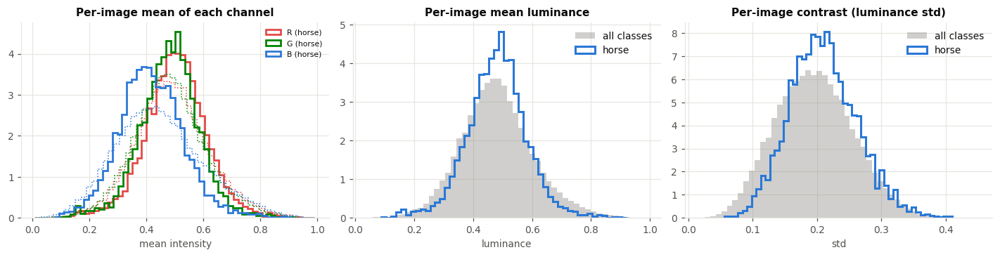

mean luminance  horse: 0.479   all: 0.481
mean contrast   horse: 0.209   all: 0.196


In [6]:
# Colour / brightness statistics of the chosen class vs. the whole dataset
def img_stats(X):
    Xf = X.astype(np.float32) / 255
    lum = 0.299 * Xf[:, 0] + 0.587 * Xf[:, 1] + 0.114 * Xf[:, 2]
    return Xf.mean(axis=(2, 3)), lum.mean(axis=(1, 2)), lum.std(axis=(1, 2))
cm_h, lum_h, con_h = img_stats(X_train)
cm_a, lum_a, con_a = img_stats(Xtr_all)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for c, (nm, col) in enumerate(zip("RGB", ["#e34948", "#008300", "#2a78d6"])):
    axes[0].hist(cm_h[:, c], bins=50, histtype="step", color=col, lw=1.8, label=f"{nm} ({CFG.class_name})", density=True)
    axes[0].hist(cm_a[:, c], bins=50, histtype="step", color=col, lw=1, ls=":", density=True)
axes[0].set_title("Per-image mean of each channel"); axes[0].set_xlabel("mean intensity"); axes[0].legend(fontsize=7)
axes[1].hist(lum_a, bins=50, density=True, color=INK3, alpha=0.4, label="all classes")
axes[1].hist(lum_h, bins=50, density=True, histtype="step", color=PALETTE[0], lw=2, label=CFG.class_name)
axes[1].set_title("Per-image mean luminance"); axes[1].set_xlabel("luminance"); axes[1].legend()
axes[2].hist(con_a, bins=50, density=True, color=INK3, alpha=0.4, label="all classes")
axes[2].hist(con_h, bins=50, density=True, histtype="step", color=PALETTE[0], lw=2, label=CFG.class_name)
axes[2].set_title("Per-image contrast (luminance std)"); axes[2].set_xlabel("std"); axes[2].legend()
plt.tight_layout(); savefig(fig, "fig02_class_statistics.png"); plt.show()
print(f"mean luminance  {CFG.class_name}: {lum_h.mean():.3f}   all: {lum_a.mean():.3f}")
print(f"mean contrast   {CFG.class_name}: {con_h.mean():.3f}   all: {con_a.mean():.3f}")

## 1.2 Building the multi-resolution training set

ProGAN needs real images at the resolution currently being trained. Following the official
implementation:

* **below 32 × 32** (4, 8, 16) the real images are produced by **2 × 2 average pooling**
  (box-filter down-sampling), repeated as needed;
* **at 32 × 32** the original images are used;
* **above 32 × 32** (64, 128) there is no real higher-resolution data, so the images are
  **bicubically upsampled** (choice justified in §1.3);
* during a **fade-in** the real images are faded exactly like the networks: the batch is
  `alpha · x_r + (1 − alpha) · up(down(x_r))`, so the discriminator sees real and fake images
  with matching blur during the transition (otherwise it could tell them apart by sharpness
  alone);
* **horizontal flips** (p = 0.5) double the effective data. A horse facing left is still a
  horse, so this changes no semantics.

All 5 000 images live on the GPU as one tensor, and every batch is built on the GPU by indexing,
flipping and resizing. This avoids a `DataLoader` (and the Windows worker problems that came
with it in Assignment 11).

In [7]:
X32 = torch.from_numpy(X_train).float().div(127.5).sub(1).to(DEV)   # (5000,3,32,32) in [-1,1]
X32_test = torch.from_numpy(X_test).float().div(127.5).sub(1).to(DEV)

def resize_real(x32, res):
    # real images at any ProGAN resolution from the native 32x32 tensor
    if res < 32:
        return F.avg_pool2d(x32, 32 // res)
    if res == 32:
        return x32
    return F.interpolate(x32, size=(res, res), mode="bicubic", align_corners=False).clamp(-1, 1)

def sample_real(res, n, alpha=1.0, flip=True):
    x = X32[torch.randint(0, len(X32), (n,), device=DEV)]
    if flip:
        m = torch.rand(n, 1, 1, 1, device=DEV) < 0.5
        x = torch.where(m, x.flip(3), x)
    x = resize_real(x, res)
    if alpha < 1.0 and res > 4:                              # fade the reals like the networks
        low = F.interpolate(F.avg_pool2d(x, 2), scale_factor=2, mode="nearest")
        x = alpha * x + (1 - alpha) * low
    return x

for r in (4, 8, 16, 32, 64, 128):
    b = sample_real(r, 8)
    print(f"res {r:3d}: batch {tuple(b.shape)}  range [{b.min():.2f}, {b.max():.2f}]")

res   4: batch (8, 3, 4, 4)  range [-0.95, 0.95]
res   8: batch (8, 3, 8, 8)  range [-0.92, 0.92]
res  16: batch (8, 3, 16, 16)  range [-0.97, 0.98]
res  32: batch (8, 3, 32, 32)  range [-1.00, 1.00]
res  64: batch (8, 3, 64, 64)  range [-1.00, 1.00]
res 128: batch (8, 3, 128, 128)  range [-1.00, 1.00]


## 1.3 How should 32 × 32 images be enlarged?

The choice of upsampling filter defines the target distribution at 64 and 128, so four filters
were compared. Nearest-neighbour produces visible 4 × 4 blocks, which the generator would
then have to learn to imitate. Bilinear is smooth but noticeably softer. Bicubic and Lanczos keep
edges sharper; Lanczos adds slightly more ringing (halo) around strong edges. **Bicubic** is used:
it is close to Lanczos in sharpness, has less ringing, and runs natively on the GPU
(`F.interpolate`).

saved -> outputs\figures\fig03_upsampling_methods.png


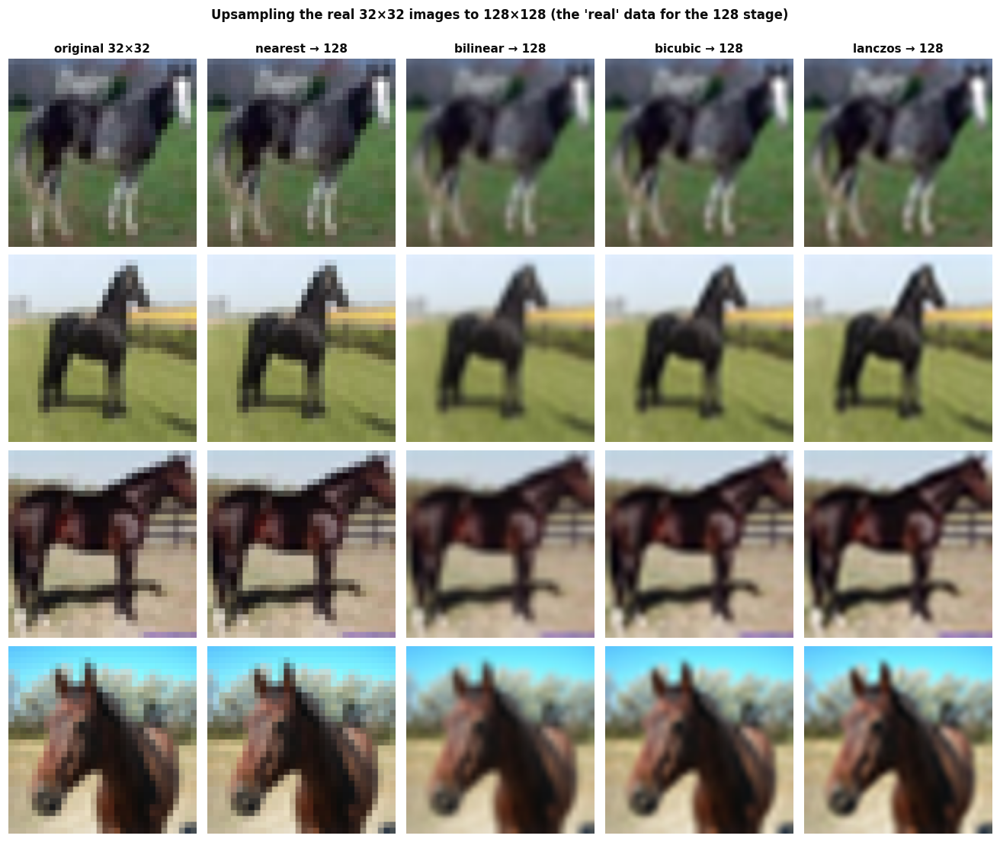

  method  mean gradient magnitude @128
 nearest                         7.572
bilinear                         6.958
 bicubic                         7.782
 lanczos                         8.236


In [8]:
pick = torch.from_numpy(X_train[[3, 17, 42, 99]])
methods = {"nearest": Image.NEAREST, "bilinear": Image.BILINEAR, "bicubic": Image.BICUBIC, "lanczos": Image.LANCZOS}
fig, axes = plt.subplots(len(pick), 5, figsize=(12, 10))
for i, im in enumerate(pick):
    pil = Image.fromarray(im.permute(1, 2, 0).numpy())
    axes[i, 0].imshow(pil.resize((128, 128), Image.NEAREST)); axes[i, 0].set_title("original 32×32" if i == 0 else "")
    for j, (nm, m) in enumerate(methods.items(), 1):
        axes[i, j].imshow(pil.resize((128, 128), m)); axes[i, j].set_title(f"{nm} → 128" if i == 0 else "")
for a in axes.ravel(): a.axis("off")
plt.suptitle("Upsampling the real 32×32 images to 128×128 (the 'real' data for the 128 stage)", y=1.0, fontweight="bold")
plt.tight_layout(); savefig(fig, "fig03_upsampling_methods.png"); plt.show()

# sharpness (mean gradient magnitude) of each method at 128 -- higher = sharper
def sharp(a):
    a = a.astype(np.float32).mean(-1); return np.abs(np.diff(a, axis=0)).mean() + np.abs(np.diff(a, axis=1)).mean()
rows = []
for nm, m in methods.items():
    v = [sharp(np.asarray(Image.fromarray(x.transpose(1, 2, 0)).resize((128, 128), m))) for x in X_train[:500]]
    rows.append({"method": nm, "mean gradient magnitude @128": np.mean(v)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# save a few prepared training images at all three assignment resolutions
(DATA / "prepared_examples").mkdir(exist_ok=True)
for r in (32, 64, 128):
    xs = to_uint8(resize_real(X32[:8], r))
    for k, x in enumerate(xs):
        Image.fromarray(x.permute(1, 2, 0).numpy()).save(DATA / "prepared_examples" / f"real_{r:03d}_{k}.png")

---
# 2. The ProGAN model

## 2.1 Building blocks

| Component | What it does | Why ProGAN needs it |
|---|---|---|
| **Equalised learning rate** (`WSConv2d`, `WSLinear`) | Weights are initialised from N(0, 1) and multiplied **at run time** by the He constant √(2 / fan-in). | Adam normalises updates per parameter, so parameters with a large dynamic range learn slowly. Scaling at run time puts every layer on the same effective learning rate, which matters when layers of very different ages (old vs. just-added) train together. |
| **Pixel-wise feature normalisation** (`PixelNorm`) | After every generator conv, each pixel's feature vector is scaled to unit RMS across channels. | Stops the generator and discriminator magnitudes from escalating against each other; it replaces batch norm (which ProGAN deliberately avoids). |
| **Minibatch standard deviation** | Before the last discriminator block, the std of every feature across a group of 4 samples is averaged into one extra feature map. | Lets the discriminator see *batch* statistics. If the generator produces near-identical images (mode collapse) that std is near zero, and the discriminator can use that to tell fakes apart. |
| **Fade-in** (`alpha`) | A new block's output is blended with the upsampled (G) / downsampled (D) output of the previous resolution, `alpha` going 0 → 1. | Prevents the "shock" of suddenly adding randomly initialised layers to a trained network. |
| **WGAN-GP + drift** | Critic loss `D(fake) − D(real) + λ·GP + ε·D(real)²`. | The loss from the paper; the drift term keeps the critic's output from drifting far from zero. |

The weight-scaling is applied to the **weights** (`F.conv2d(x, w·c)`) rather than to the input
(`conv(x·c)`). The two are mathematically identical, but scaling the input stores an extra copy of every
activation for back-prop, and the gradient penalty differentiates through the network twice, so
every saved activation counts. Together with the two changes in §4.1 this brought 128 × 128 training
from 17 GB (more than the GPU has) down to 4–8 GB (§10).

In [9]:
class WSConv2d(nn.Module):
    # convolution with equalised learning rate
    def __init__(self, cin, cout, k=3, s=1, p=1, gain=2.0):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(cout, cin, k, k))
        self.bias = nn.Parameter(torch.zeros(cout))
        self.scale, self.s, self.p = math.sqrt(gain / (cin * k * k)), s, p
    def forward(self, x):
        return F.conv2d(x, self.weight * self.scale, self.bias, self.s, self.p)

class WSLinear(nn.Module):
    def __init__(self, cin, cout, gain=2.0):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(cout, cin))
        self.bias = nn.Parameter(torch.zeros(cout))
        self.scale = math.sqrt(gain / cin)
    def forward(self, x):
        return F.linear(x, self.weight * self.scale, self.bias)

class PixelNorm(nn.Module):
    def forward(self, x, eps=1e-8):
        return x * torch.rsqrt(x.float().pow(2).mean(dim=1, keepdim=True) + eps).to(x.dtype)

def minibatch_std(x, group=4):
    b, c, h, w = x.shape
    g = min(group, b)
    while b % g:
        g -= 1
    y = x.float().view(g, -1, c, h, w)
    y = (y - y.mean(0)).pow(2).mean(0).add(1e-8).sqrt()          # std over the group
    y = y.mean(dim=[1, 2, 3]).view(-1, 1, 1, 1).repeat(g, 1, h, w)
    return torch.cat([x, y.to(x.dtype)], 1)

## 2.2 Generator and Discriminator

Both networks are built **once at full size** (all six resolutions) but only the first
`step + 1` resolution blocks are used in the forward pass; `step = log2(res) − 2`. This makes
growing trivial (just increase `step`) and keeps every parameter in the same object for the EMA.

**Generator.** `z ∈ R^256` → PixelNorm → fully-connected to 256 × 4 × 4 → 3 × 3 conv. Each
further block is *nearest ×2 upsample → 3 × 3 conv → LeakyReLU(0.2) → PixelNorm*, twice.
Every resolution has its own 1 × 1 `toRGB` layer with a linear output (no `tanh`, as in the paper).

**Discriminator.** The mirror image: a 1 × 1 `fromRGB` per resolution, blocks of two 3 × 3 convs +
LeakyReLU followed by 2 × 2 average pooling, and a final 4 × 4 block containing the minibatch-std
layer, a 3 × 3 conv, a 4 × 4 valid conv and a linear output. No normalisation in D (WGAN-GP's
penalty is defined per sample, so batch norm in D is not allowed).

**Fade-in** for the step being added (`alpha < 1`):

* G: `out = alpha · toRGB_s(block_s(up(h))) + (1 − alpha) · up(toRGB_{s−1}(h))`
* D: `h = alpha · pool(block_s(fromRGB_s(x))) + (1 − alpha) · fromRGB_{s−1}(pool(x))`

In [10]:
class GBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.c1, self.c2 = WSConv2d(cin, cout), WSConv2d(cout, cout)
        self.act, self.pn = nn.LeakyReLU(0.2), PixelNorm()
    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        x = self.pn(self.act(self.c1(x)))
        return self.pn(self.act(self.c2(x)))

class DBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.c1, self.c2 = WSConv2d(cin, cin), WSConv2d(cin, cout)
        self.act = nn.LeakyReLU(0.2)
    def forward(self, x):
        return F.avg_pool2d(self.act(self.c2(self.act(self.c1(x)))), 2)

class Generator(nn.Module):
    def __init__(self, z_dim, chans):
        super().__init__()
        self.z_dim, self.chans = z_dim, list(chans)
        c0 = chans[0]
        self.pn, self.act = PixelNorm(), nn.LeakyReLU(0.2)
        self.fc = WSLinear(z_dim, c0 * 16, gain=2.0 / 16)    # gain as in the official code
        self.conv0 = WSConv2d(c0, c0)
        self.blocks = nn.ModuleList([GBlock(chans[i - 1], chans[i]) for i in range(1, len(chans))])
        self.to_rgb = nn.ModuleList([WSConv2d(c, 3, 1, 1, 0, gain=1.0) for c in chans])

    def forward(self, z, step, alpha=1.0):
        x = self.act(self.fc(self.pn(z))).view(z.size(0), -1, 4, 4)
        x = self.pn(self.act(self.conv0(self.pn(x))))
        prev = x
        for i in range(step):
            prev = x
            x = self.blocks[i](x)
        out = self.to_rgb[step](x)
        if alpha < 1.0 and step > 0:
            skip = F.interpolate(self.to_rgb[step - 1](prev), scale_factor=2, mode="nearest")
            out = alpha * out + (1 - alpha) * skip
        return out

class Discriminator(nn.Module):
    def __init__(self, chans):
        super().__init__()
        self.chans = list(chans)
        c0 = chans[0]
        self.from_rgb = nn.ModuleList([WSConv2d(3, c, 1, 1, 0) for c in chans])
        # blocks[i] maps resolution i -> i-1 ; blocks[0] is unused (the final block handles 4x4)
        self.blocks = nn.ModuleList([nn.Identity()] + [DBlock(chans[i], chans[i - 1]) for i in range(1, len(chans))])
        self.final_conv  = WSConv2d(c0 + 1, c0)
        self.final_conv4 = WSConv2d(c0, c0, 4, 1, 0)
        self.final_lin   = WSLinear(c0, 1, gain=1.0)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, step, alpha=1.0):
        h = self.act(self.from_rgb[step](x))
        if step > 0:
            h = self.blocks[step](h)
            if alpha < 1.0:
                h = alpha * h + (1 - alpha) * self.act(self.from_rgb[step - 1](F.avg_pool2d(x, 2)))
            for i in range(step - 1, 0, -1):
                h = self.blocks[i](h)
        h = minibatch_std(h)
        h = self.act(self.final_conv(h))
        h = self.act(self.final_conv4(h)).flatten(1)
        return self.final_lin(h)

def res2step(r): return int(math.log2(r)) - 2

# --------------------------------------------------- sanity check every resolution and alpha
G_tmp, D_tmp = Generator(CFG.z_dim, CFG.chans).to(DEV), Discriminator(CFG.chans).to(DEV)
with torch.no_grad():
    for r in (4, 8, 16, 32, 64, 128):
        for a in (0.0, 0.5, 1.0):
            img = G_tmp(torch.randn(4, CFG.z_dim, device=DEV), res2step(r), a)
            sc = D_tmp(img, res2step(r), a)
            assert img.shape == (4, 3, r, r) and sc.shape == (4, 1)
        print(f"res {r:3d}: G -> {tuple(img.shape)}   D -> {tuple(sc.shape)}   (alpha 0 / 0.5 / 1 all OK)")

res   4: G -> (4, 3, 4, 4)   D -> (4, 1)   (alpha 0 / 0.5 / 1 all OK)
res   8: G -> (4, 3, 8, 8)   D -> (4, 1)   (alpha 0 / 0.5 / 1 all OK)
res  16: G -> (4, 3, 16, 16)   D -> (4, 1)   (alpha 0 / 0.5 / 1 all OK)
res  32: G -> (4, 3, 32, 32)   D -> (4, 1)   (alpha 0 / 0.5 / 1 all OK)
res  64: G -> (4, 3, 64, 64)   D -> (4, 1)   (alpha 0 / 0.5 / 1 all OK)
res 128: G -> (4, 3, 128, 128)   D -> (4, 1)   (alpha 0 / 0.5 / 1 all OK)


## 2.3 Architecture and parameter count per resolution

The table lists, for every resolution, the layers that are *added* when the network grows to
that resolution, their parameters and the multiply-accumulate operations (MACs) for one image.
The "active" columns give the size of the network that is actually trained at that stage.

In [11]:
def n_params(m): return sum(p.numel() for p in m.parameters())

rows = []
chans = CFG.chans
for s, r in enumerate((4, 8, 16, 32, 64, 128)):
    c = chans[s]
    if s == 0:
        g_new = n_params(G_tmp.fc) + n_params(G_tmp.conv0) + n_params(G_tmp.to_rgb[0])
        d_new = (n_params(D_tmp.from_rgb[0]) + n_params(D_tmp.final_conv) + n_params(D_tmp.final_conv4)
                 + n_params(D_tmp.final_lin))
        g_mac = CFG.z_dim * c * 16 + c * c * 9 * 16 + c * 3 * 16
        g_layers = f"FC {CFG.z_dim}→{c}×4×4, conv3×3 {c}→{c}"
        d_layers = f"mbstd, conv3×3 {c+1}→{c}, conv4×4 {c}→{c}, FC {c}→1"
    else:
        g_new = n_params(G_tmp.blocks[s - 1]) + n_params(G_tmp.to_rgb[s])
        d_new = n_params(D_tmp.blocks[s]) + n_params(D_tmp.from_rgb[s])
        g_mac = (chans[s - 1] * c * 9 + c * c * 9 + c * 3) * r * r
        g_layers = f"up×2, conv3×3 {chans[s-1]}→{c}, conv3×3 {c}→{c}"
        d_layers = f"conv3×3 {c}→{c}, conv3×3 {c}→{chans[s-1]}, avgpool"
    rows.append({"res": f"{r}×{r}", "channels": c, "G layers added": g_layers, "G params added": g_new,
                 "D layers added": d_layers, "D params added": d_new, "G MACs added (M)": g_mac / 1e6})
arch = pd.DataFrame(rows)
arch["G params active"] = arch["G params added"].cumsum()
arch["D params active"] = arch["D params added"].cumsum()
arch["G MACs active (M)"] = arch["G MACs added (M)"].cumsum()
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
display(arch.style.format({"G params added": "{:,}", "D params added": "{:,}", "G params active": "{:,}",
                           "D params active": "{:,}", "G MACs added (M)": "{:.1f}", "G MACs active (M)": "{:.1f}"}))
arch.to_csv(RES / "architecture.csv", index=False)
print(f"Total G parameters: {n_params(G_tmp):,}   Total D parameters: {n_params(D_tmp):,}")
del G_tmp, D_tmp

,res,channels,G layers added,G params added,D layers added,D params added,G MACs added (M),G params active,D params active,G MACs active (M)
0,4×4,256,"FC 256→256×4×4, conv3×3 256→256","1,643,523","mbstd, conv3×3 257→256, conv4×4 256→256, FC 256→1","1,642,497",10.5,"1,643,523","1,642,497",10.5
1,8×8,256,"up×2, conv3×3 256→256, conv3×3 256→256","1,180,931","conv3×3 256→256, conv3×3 256→256, avgpool","1,181,184",75.5,"2,824,454","2,823,681",86.0
2,16×16,256,"up×2, conv3×3 256→256, conv3×3 256→256","1,180,931","conv3×3 256→256, conv3×3 256→256, avgpool","1,181,184",302.2,"4,005,385","4,004,865",388.2
3,32×32,256,"up×2, conv3×3 256→256, conv3×3 256→256","1,180,931","conv3×3 256→256, conv3×3 256→256, avgpool","1,181,184",1208.7,"5,186,316","5,186,049",1597.0
4,64×64,128,"up×2, conv3×3 256→128, conv3×3 128→128","443,011","conv3×3 128→128, conv3×3 128→256, avgpool","443,264",1813.5,"5,629,327","5,629,313",3410.5
5,128×128,64,"up×2, conv3×3 128→64, conv3×3 64→64","110,915","conv3×3 64→64, conv3×3 64→128, avgpool","111,040",1815.1,"5,740,242","5,740,353",5225.6


Total G parameters: 5,740,242   Total D parameters: 5,740,353


---
# 3. Evaluation tooling (needed during training for FID tracking)

* **FID** (Fréchet Inception Distance; Heusel *et al.*, 2017): distance between Gaussians fitted to
  Inception-v3 pool features (2048-d) of real and generated images. Lower is better. It is biased
  upward for small sample sizes, so FIDs are only compared at equal *N*.
* **KID** (Kernel Inception Distance; Bińkowski *et al.*, 2018): unbiased squared MMD with a
  cubic polynomial kernel on the same features; mean ± std over 100 subsets of 1 000. Reliable at
  small *N* and ≈ 0 for two real samples. Reported × 10³.
* **Precision / Recall** (Kynkäänniemi *et al.*, 2019, k = 3): precision = fraction of generated
  samples that land inside the real-data manifold (≈ *fidelity*); recall = fraction of real
  samples inside the generated manifold (≈ *diversity / coverage*). FID mixes the two; P/R
  separates them.

Images are fed to the TF-compatible Inception-v3 from `torch-fidelity` as `uint8` at their
native resolution; the extractor resizes to 299 × 299 internally, the same way for real and
fake.

In [12]:
from torch_fidelity.feature_extractor_inceptionv3 import FeatureExtractorInceptionV3
INCEPTION = FeatureExtractorInceptionV3("inception-v3-compat", ["2048"]).to(DEV).eval()

@torch.no_grad()
def inception_feats(x, bs=250):
    # x: float [-1,1] or uint8, NCHW, any device -> (N,2048) float64 numpy
    out = []
    for i in range(0, len(x), bs):
        b = x[i:i + bs]
        b = b.to(DEV) if b.dtype == torch.uint8 else to_uint8(b).to(DEV)
        out.append(INCEPTION(b)[0].double().cpu())
    return torch.cat(out).numpy()

def feat_stats(f): return f.mean(0), np.cov(f, rowvar=False)

def fid_from_stats(m1, s1, m2, s2):
    diff = m1 - m2
    covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
    if not np.isfinite(covmean).all():
        off = np.eye(s1.shape[0]) * 1e-6
        covmean = linalg.sqrtm((s1 + off) @ (s2 + off))
    covmean = covmean.real
    return float(diff @ diff + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def kid(f1, f2, n_sub=100, sub=1000, seed=0):
    rng = np.random.default_rng(seed)
    a, b = torch.from_numpy(f1).to(DEV), torch.from_numpy(f2).to(DEV)
    d, m = a.shape[1], min(sub, len(a), len(b))
    vals = []
    for _ in range(n_sub):
        x = a[rng.choice(len(a), m, replace=False)]; y = b[rng.choice(len(b), m, replace=False)]
        kxx = (x @ x.T / d + 1) ** 3; kyy = (y @ y.T / d + 1) ** 3; kxy = (x @ y.T / d + 1) ** 3
        mmd = ((kxx.sum() - kxx.diag().sum()) / (m * (m - 1)) + (kyy.sum() - kyy.diag().sum()) / (m * (m - 1))
               - 2 * kxy.mean())
        vals.append(mmd.item())
    return float(np.mean(vals)), float(np.std(vals))

def precision_recall(real_f, fake_f, k=3):
    r, f = torch.from_numpy(real_f).float().to(DEV), torch.from_numpy(fake_f).float().to(DEV)
    def radii(x):
        d = torch.cdist(x, x); return d.kthvalue(k + 1, dim=1).values      # +1 skips self
    rr, rf = radii(r), radii(f)
    prec = (torch.cdist(f, r) <= rr[None, :]).any(1).float().mean().item()
    rec  = (torch.cdist(r, f) <= rf[None, :]).any(1).float().mean().item()
    return prec, rec

# ----------------------------------------------------- real reference features per resolution
t = time.time()
REAL_FEATS, REAL_STATS = {}, {}
for r in (16, 32, 64, 128):
    REAL_FEATS[r] = inception_feats(resize_real(X32, r))
    REAL_STATS[r] = feat_stats(REAL_FEATS[r])
TEST_FEATS = {r: inception_feats(resize_real(X32_test, r)) for r in (32, 64, 128)}
print(f"real Inception features for res 16/32/64/128 + test set: {time.time() - t:.1f}s")

# Real-vs-real floor: what a perfect generator would score with the same sample sizes
for r in (32, 64, 128):
    f_tr = REAL_FEATS[r]
    print(f"res {r:3d}: FID(test 1k vs train 5k) = {fid_from_stats(*feat_stats(TEST_FEATS[r]), *REAL_STATS[r]):6.2f}"
          f"   KID x1e3 = {1e3 * kid(TEST_FEATS[r], f_tr)[0]:.3f}")

real Inception features for res 16/32/64/128 + test set: 20.8s


res  32: FID(test 1k vs train 5k) =  24.33   KID x1e3 = 0.032


res  64: FID(test 1k vs train 5k) =  24.19   KID x1e3 = 0.057


res 128: FID(test 1k vs train 5k) =  25.29   KID x1e3 = 0.067


---
# 4. Training procedure

## 4.1 Schedule and optimisation

Training progress is measured in **kimg** (thousands of real images shown to D), as in the
paper. Each resolution has a **fade-in** phase (`alpha` rises linearly 0 → 1) followed by a
**stabilisation** phase (`alpha = 1`). The 32 × 32 stage gets the largest budget because it is the
**native** resolution of the data and therefore where nearly all of the real image content is
learned. The 64 and 128 stages mainly have to learn to *upsample faithfully*.

| | 4² | 8² | 16² | **32²** | **64²** | **128²** |
|---|---|---|---|---|---|---|
| fade-in kimg | – | 120 | 120 | 200 | 150 | 150 |
| stabilise kimg | 120 | 120 | 120 | 400 | 250 | 250 |

Per iteration: one critic update and one generator update (n_critic = 1 as in ProGAN), batch 64,
Adam (lr = 10⁻³, β = (0, 0.99), ε = 10⁻⁸). **The optimiser state is reset at every new
resolution**, as in the official code, because the old Adam moments belong to a differently
shaped problem.

**Two engineering changes from the paper, both for speed and memory:**

1. **Lazy gradient penalty.** The WGAN-GP penalty needs a second backward pass through D. It is
   computed every `gp_every = 4` critic steps on `gp_batch = 32` interpolated samples and multiplied
   by 4 so its average strength equals λ = 10 per step. StyleGAN2 introduced this "lazy
   regularisation" for R1 and showed no quality loss. Measured here (with bf16): 1.4× throughput at 32 × 32
   (694 → 956 img/s) and 1.9× at 128 × 128 (108 → 201 img/s).
2. **bfloat16 autocast.** bf16 keeps the fp32 exponent range, so no loss scaling is required. The
   numerically delicate reductions (PixelNorm, minibatch std, losses, gradient norm) are forced
   to fp32.

The **EMA generator** (`β = 0.999`) is the one used for every sample and metric unless stated
otherwise. Metric snapshots: quick FID (2 000 samples vs. the 5 000 training images) every 50 kimg
from 16 × 16 upward, and a fixed set of 16 latent vectors rendered every 20 kimg to watch
the same "individuals" develop.

 res  fade kimg  stab kimg  start kimg  end kimg  iterations
   4          0        120           0       120        1875
   8        120        120         120       360        3750
  16        120        120         360       600        3750
  32        200        400         600      1200        9375
  64        150        250        1200      1600        6251
 128        150        250        1600      2000        6251
total kimg: 2000  total iterations: 31252
saved -> outputs\figures\fig04_schedule.png


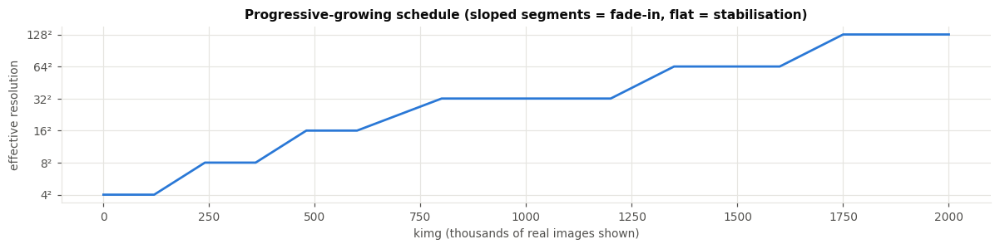

In [13]:
def schedule_table(sched):
    rows, k = [], 0
    for r, (fk, sk) in sched.items():
        rows.append({"res": r, "fade kimg": fk, "stab kimg": sk, "start kimg": k, "end kimg": k + fk + sk,
                     "iterations": math.ceil(fk * 1000 / CFG.batch) + math.ceil(sk * 1000 / CFG.batch)})
        k += fk + sk
    return pd.DataFrame(rows)
sched_df = schedule_table(CFG.schedule)
print(sched_df.to_string(index=False))
print("total kimg:", sched_df["end kimg"].iloc[-1], " total iterations:", sched_df["iterations"].sum())
sched_df.to_csv(RES / "schedule.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 2.8))
xs, ys, al = [], [], []
k = 0
for r, (fk, sk) in CFG.schedule.items():
    s = res2step(r)
    if fk:
        xx = np.linspace(k, k + fk, 50); xs += list(xx); ys += list(s - 1 + (xx - k) / fk)
    xs += [k + fk, k + fk + sk]; ys += [s, s]
    k += fk + sk
ax.plot(xs, ys, color=PALETTE[0])
ax.set_yticks(range(6)); ax.set_yticklabels([f"{4 * 2 ** i}²" for i in range(6)])
ax.set_xlabel("kimg (thousands of real images shown)"); ax.set_ylabel("effective resolution")
ax.set_title("Progressive-growing schedule (sloped segments = fade-in, flat = stabilisation)")
plt.tight_layout(); savefig(fig, "fig04_schedule.png"); plt.show()

## 4.2 The training loop

`train_gan()` runs any schedule (the same function is reused for the non-progressive ablation in §9).
It writes a checkpoint at the end of each resolution stage, containing G, D, the EMA generator and
the full history, and a partial checkpoint (including optimiser state) every 50 kimg inside a stage.
Re-running the notebook therefore **resumes** where it stopped instead of retraining. A plain-text progress log is written to `outputs/results/train_<tag>.log`.

In [14]:
def ema_update(g_ema, g, beta):
    with torch.no_grad():
        torch._foreach_lerp_(list(g_ema.parameters()), list(g.parameters()), 1 - beta)

@torch.no_grad()
def generate(G, n, step, alpha=1.0, seed=0, bs=500, z=None):
    # uint8 NCHW on CPU
    g = torch.Generator(device=DEV).manual_seed(seed)
    out = []
    for i in range(0, n, bs):
        m = min(bs, n - i)
        zz = torch.randn(m, G.z_dim, device=DEV, generator=g) if z is None else z[i:i + m].to(DEV)
        out.append(to_uint8(G(zz, step, alpha)))
    return torch.cat(out)

def quick_fid(G, res, alpha, n):
    f = inception_feats(generate(G, n, res2step(res), alpha, seed=123))
    return fid_from_stats(*feat_stats(f), *REAL_STATS[res])

Z_FIXED = torch.randn(16, CFG.z_dim, generator=torch.Generator().manual_seed(2024)).to(DEV)

def train_gan(schedule, tag, cfg=CFG, log_every=50):
    ckfile = lambda r: CKPT / f"{tag}_res{r:03d}.pt"
    final = ckfile(list(schedule)[-1])
    if final.exists():
        ck = torch.load(final, map_location="cpu", weights_only=False)
        print(f"[{tag}] found finished run -> loaded {final.name}")
        return ck["hist"]

    torch.cuda.empty_cache()
    set_seed(cfg.seed)
    G = Generator(cfg.z_dim, cfg.chans).to(DEV)
    D = Discriminator(cfg.chans).to(DEV)
    G_ema = copy.deepcopy(G).eval().requires_grad_(False)
    hist = {"log": [], "fid": [], "snaps": [], "phases": [], "stage_time": {}}
    kimg, t_used = 0.0, 0.0

    # ---------- resume from the last completed stage, if any
    start = 0
    for i, r in enumerate(schedule):
        if ckfile(r).exists():
            start = i + 1
    if start:
        ck = torch.load(ckfile(list(schedule)[start - 1]), map_location="cpu", weights_only=False)
        G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"]); G_ema.load_state_dict(ck["G_ema"])
        hist, kimg, t_used = ck["hist"], ck["kimg"], ck["t_used"]
        print(f"[{tag}] resuming after res {list(schedule)[start - 1]} (kimg {kimg:.0f})")

    # ---------- resume inside an unfinished stage (partial checkpoint every ~50 kimg)
    pfile, resume = CKPT / f"{tag}_partial.pt", None
    if pfile.exists():
        pc = torch.load(pfile, map_location="cpu", weights_only=False)
        if start < len(schedule) and pc["res"] == list(schedule)[start]:
            resume = pc
            G.load_state_dict(pc["G"]); D.load_state_dict(pc["D"]); G_ema.load_state_dict(pc["G_ema"])
            hist, kimg, t_used = pc["hist"], pc["kimg"], pc["t_used"]
            print(f"[{tag}] resuming inside res {pc['res']} ({pc['phase']}, kimg {kimg:.0f})")
    ckpt_iters = math.ceil(50_000 / cfg.batch)

    logf = open(RES / f"train_{tag}.log", "a")
    B = cfg.batch
    for r in list(schedule)[start:]:
        step = res2step(r)
        fade_k, stab_k = schedule[r]
        optG = torch.optim.Adam(G.parameters(), cfg.lr, betas=cfg.betas, eps=1e-8)   # reset per stage
        optD = torch.optim.Adam(D.parameters(), cfg.lr, betas=cfg.betas, eps=1e-8)
        if resume is not None:
            optG.load_state_dict(resume["optG"]); optD.load_state_dict(resume["optD"])
        t_stage = time.time() - (resume["stage_elapsed"] if resume is not None else 0.0)
        for phase, pk in (("fade", fade_k), ("stab", stab_k)):
            if pk == 0 or (resume is not None and resume["phase"] == "stab" and phase == "fade"):
                continue
            n_it = math.ceil(pk * 1000 / B)
            it0, k0 = (resume["it"], resume["k0"]) if resume is not None else (0, kimg)
            resume = None
            next_fid = (math.floor(kimg / cfg.fid_every_kimg) + 1) * cfg.fid_every_kimg
            next_snap = (math.floor(kimg / cfg.snap_every_kimg) + 1) * cfg.snap_every_kimg
            buf = []
            t0 = time.time()
            for it in range(it0, n_it):
                alpha = (it + 1) / n_it if phase == "fade" else 1.0
                # ------------------------------------------------ critic step
                real = sample_real(r, B, alpha)
                z = torch.randn(B, cfg.z_dim, device=DEV)
                with torch.autocast("cuda", torch.bfloat16, enabled=cfg.amp):
                    with torch.no_grad():
                        fake = G(z, step, alpha)
                    d_real = D(real, step, alpha).float()
                    d_fake = D(fake, step, alpha).float()
                w_dist = d_real.mean() - d_fake.mean()
                lossD = -w_dist + cfg.drift * d_real.pow(2).mean()
                if it % cfg.gp_every == 0 or it == it0:
                    n = cfg.gp_batch
                    eps = torch.rand(n, 1, 1, 1, device=DEV)
                    xh = (eps * real[:n] + (1 - eps) * fake[:n].float()).requires_grad_(True)
                    with torch.autocast("cuda", torch.bfloat16, enabled=cfg.amp):
                        out = D(xh, step, alpha).float()
                    grad, = torch.autograd.grad(out.sum(), xh, create_graph=True)
                    gp = (grad.float().flatten(1).norm(dim=1) - 1).pow(2).mean()
                    lossD = lossD + cfg.gp_lambda * cfg.gp_every * gp
                    gp_val = gp.detach()
                optD.zero_grad(set_to_none=True); lossD.backward(); optD.step()
                # ------------------------------------------------ generator step
                z = torch.randn(B, cfg.z_dim, device=DEV)
                with torch.autocast("cuda", torch.bfloat16, enabled=cfg.amp):
                    lossG = -D(G(z, step, alpha), step, alpha).float().mean()
                optG.zero_grad(set_to_none=True); lossG.backward(); optG.step()
                ema_update(G_ema, G, cfg.ema_beta)

                kimg += B / 1000
                buf.append(torch.stack([lossD.detach(), lossG.detach(), w_dist.detach(), gp_val, d_real.mean().detach()]))
                fid_due = r >= 16 and (kimg >= next_fid or it == n_it - 1)
                if (it + 1) % log_every == 0 or it == n_it - 1 or fid_due:
                    v = torch.stack(buf).mean(0).tolist(); buf = []
                    hist["log"].append({"kimg": kimg, "res": r, "phase": phase, "alpha": alpha, "lossD": v[0],
                                        "lossG": v[1], "w_dist": v[2], "gp": v[3], "d_real": v[4],
                                        "time": t_used + time.time() - t_stage})
                if kimg >= next_snap or it == n_it - 1:
                    hist["snaps"].append({"kimg": kimg, "res": r, "alpha": alpha,
                                          "img": generate(G_ema, 16, step, alpha, z=Z_FIXED)})
                    next_snap += cfg.snap_every_kimg
                if fid_due:
                    fid = quick_fid(G_ema, r, alpha, cfg.fid_quick_n)
                    hist["fid"].append({"kimg": kimg, "res": r, "phase": phase, "alpha": alpha, "fid": fid,
                                        "time": t_used + time.time() - t_stage})
                    next_fid += cfg.fid_every_kimg
                    msg = (f"[{tag}] res {r:3d} {phase} a={alpha:.2f} kimg {kimg:7.1f} | D {hist['log'][-1]['lossD']:+.3f}"
                           f" G {hist['log'][-1]['lossG']:+.3f} W {hist['log'][-1]['w_dist']:.3f} | FID2k {fid:6.2f}"
                           f" | {(it + 1 - it0) * B / (time.time() - t0):.0f} img/s")
                    print(msg, flush=True); logf.write(msg + "\n"); logf.flush()
                if (it + 1) % ckpt_iters == 0 and it < n_it - 1:
                    torch.save({"G": G.state_dict(), "D": D.state_dict(), "G_ema": G_ema.state_dict(),
                                "optG": optG.state_dict(), "optD": optD.state_dict(), "hist": hist, "res": r,
                                "phase": phase, "it": it + 1, "k0": k0, "kimg": kimg, "t_used": t_used,
                                "stage_elapsed": time.time() - t_stage}, pfile)
            hist["phases"].append({"res": r, "phase": phase, "k0": k0, "k1": kimg})
        dt = time.time() - t_stage
        t_used += dt
        pfile.unlink(missing_ok=True)
        hist["stage_time"][r] = dt
        torch.save({"G": G.state_dict(), "D": D.state_dict(), "G_ema": G_ema.state_dict(), "hist": hist,
                    "kimg": kimg, "t_used": t_used, "res": r, "cfg": asdict(cfg)}, ckfile(r))
        msg = f"[{tag}] === finished {r}x{r} in {dt / 60:.1f} min (total {t_used / 60:.1f} min) -> {ckfile(r).name}"
        print(msg, flush=True); logf.write(msg + "\n"); logf.flush()
    logf.close()
    return hist

def load_generators(tag, resolutions, ema=True):
    out = {}
    for r in resolutions:
        ck = torch.load(CKPT / f"{tag}_res{r:03d}.pt", map_location=DEV, weights_only=False)
        g = Generator(CFG.z_dim, CFG.chans).to(DEV).eval()
        g.load_state_dict(ck["G_ema" if ema else "G"])
        out[r] = g
    return out

## 4.3 Run the progressive training

This is the expensive cell (about one hour on an RTX 5070 Ti). The log line printed at every FID
checkpoint shows the resolution, phase, `alpha`, losses, the critic's Wasserstein estimate `W`,
the quick FID and the throughput.

In [15]:
t = time.time()
HIST = train_gan(CFG.schedule, "progan")
print(f"cell time: {(time.time() - t) / 60:.1f} min")
stage_time = pd.Series(HIST["stage_time"]).rename("seconds").to_frame()
stage_time["minutes"] = stage_time["seconds"] / 60
stage_time["kimg"] = [sum(CFG.schedule[r]) for r in stage_time.index]
stage_time["img/s"] = stage_time["kimg"] * 1000 / stage_time["seconds"]
stage_time.index.name = "res"
print(stage_time.round(1).to_string())
stage_time.to_csv(RES / "stage_time.csv")

[progan] found finished run -> loaded progan_res128.pt
cell time: 0.0 min
     seconds  minutes  kimg   img/s
res                                
4       22.1      0.4   120  5423.6
8       65.8      1.1   240  3647.6
16     105.6      1.8   240  2271.7
32     639.5     10.7   600   938.2
64     989.7     16.5   400   404.1
128   2045.1     34.1   400   195.6


---
# 5. Training dynamics

## 5.1 Losses and the critic's Wasserstein estimate

Shaded bands mark the resolution stages; the darker part of each band is the fade-in. `W` =
`E[D(real)] − E[D(fake)]` is the critic's estimate of the Wasserstein distance. Under WGAN-GP it
is the most meaningful number in the log: it should stay small and bounded. A steady rise means
the critic is winning, typically by memorising the training set.

saved -> outputs\figures\fig05_losses.png


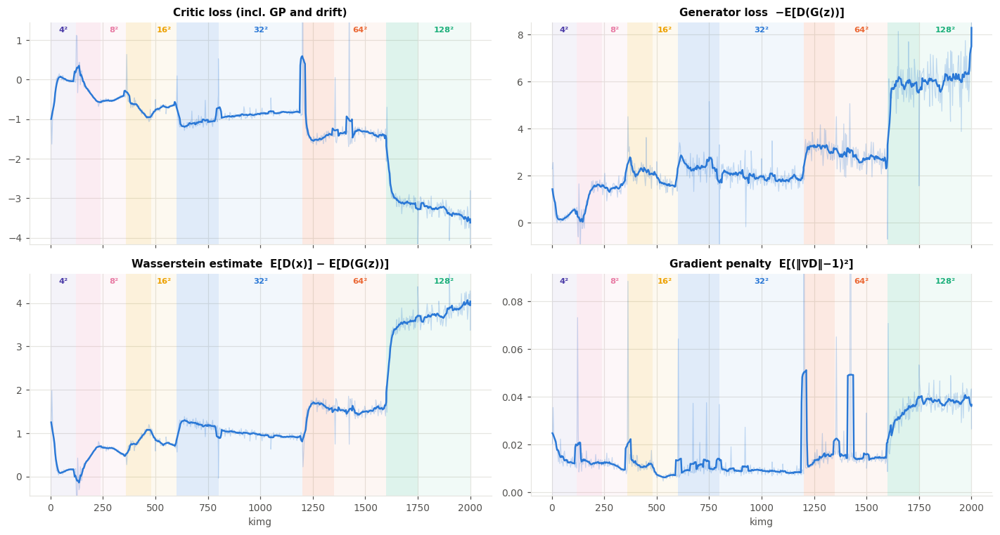

     W_mean   W_std   W_end  GP_mean  lossG_end
res                                            
4    0.3055  0.4174  0.1641   0.0153     0.5545
8    0.6040  0.0742  0.5035   0.0111     1.7739
16   0.7872  0.0997  0.7225   0.0071     1.5629
32   0.9619  0.1151  0.9188   0.0091     1.8226
64   1.5323  0.1811  1.6221   0.0191     2.2996
128  3.7951  0.2382  3.9969   0.0382     7.1567


In [16]:
log = pd.DataFrame(HIST["log"]); fidlog = pd.DataFrame(HIST["fid"]); phases = HIST["phases"]
log.to_csv(RES / "train_log.csv", index=False); fidlog.to_csv(RES / "train_fid.csv", index=False)
sm = lambda s: s.rolling(9, center=True, min_periods=1).mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
items = [("lossD", "Critic loss (incl. GP and drift)"), ("lossG", "Generator loss  −E[D(G(z))]"),
         ("w_dist", "Wasserstein estimate  E[D(x)] − E[D(G(z))]"), ("gp", "Gradient penalty  E[(‖∇D‖−1)²]")]
for ax, (k, title) in zip(axes.ravel(), items):
    ax.plot(log["kimg"], log[k], color=PALETTE[0], alpha=0.25, lw=0.8)
    ax.plot(log["kimg"], sm(log[k]), color=PALETTE[0], lw=1.6)
    stage_spans(ax, phases); ax.set_title(title)
    lo, hi = np.percentile(log[k], [1, 99.5]); pad = 0.1 * (hi - lo); ax.set_ylim(lo - pad, hi + pad)
for ax in axes[1]: ax.set_xlabel("kimg")
plt.tight_layout(); savefig(fig, "fig05_losses.png"); plt.show()

# per-stage summary of the dynamics (stabilisation phase only)
dyn = log[log.phase == "stab"].groupby("res").agg(W_mean=("w_dist", "mean"), W_std=("w_dist", "std"),
        W_end=("w_dist", lambda s: s.iloc[-10:].mean()), GP_mean=("gp", "mean"), lossG_end=("lossG", lambda s: s.iloc[-10:].mean()))
print(dyn.round(4).to_string())
dyn.to_csv(RES / "dynamics_per_stage.csv")

## 5.2 Quick FID during training

FID on 2 000 EMA samples against the 5 000 real images *at the current resolution*. Within a
stage, a falling curve means that resolution is still being learned. A jump at the start of a fade-in
is expected, because the new randomly initialised block is being blended in.

saved -> outputs\figures\fig06_fid_during_training.png


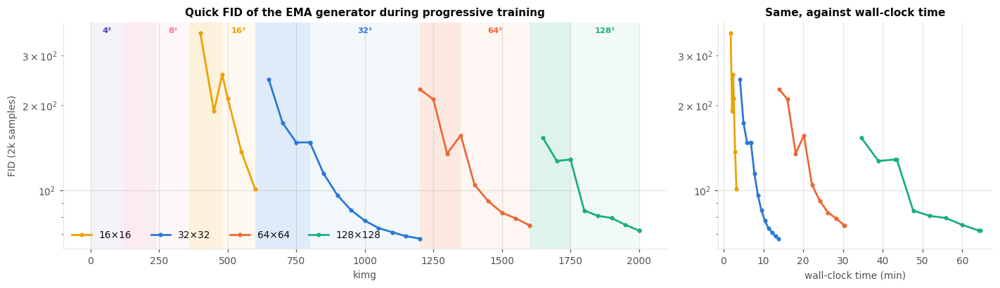

     fid_first  fid_min  fid_last  kimg_at_min
res                                           
16      361.75   100.78    100.78       600.00
32      246.60    67.28     67.28      1200.00
64      227.80    75.01     75.04      1600.00
128     152.96    71.84     71.84      2000.13


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
for r, g in fidlog.groupby("res"):
    ax.plot(g["kimg"], g["fid"], "-o", ms=3, color=RES_COLOR[r], label=f"{r}×{r}")
stage_spans(ax, phases); ax.set_xlabel("kimg"); ax.set_ylabel("FID (2k samples)"); ax.set_yscale("log")
ax.set_title("Quick FID of the EMA generator during progressive training"); ax.legend(ncol=4, loc="lower left")
ax = axes[1]
for r, g in fidlog.groupby("res"):
    ax.plot(g["time"] / 60, g["fid"], "-o", ms=3, color=RES_COLOR[r], label=f"{r}×{r}")
ax.set_xlabel("wall-clock time (min)"); ax.set_yscale("log"); ax.set_title("Same, against wall-clock time")
plt.tight_layout(); savefig(fig, "fig06_fid_during_training.png"); plt.show()

ms = fidlog.groupby("res").agg(fid_first=("fid", "first"), fid_min=("fid", "min"), fid_last=("fid", "last"),
                               kimg_at_min=("kimg", lambda s: s.loc[fidlog.loc[s.index, "fid"].idxmin()]))
print(ms.round(2).to_string()); ms.to_csv(RES / "fid_milestones.csv")

## 5.3 Watching the same latent vectors grow

The fixed vectors `Z_FIXED` were rendered every 20 kimg. Below, four of them are shown at a sequence
of training moments (every image nearest-upscaled to 128 × 128 for display). It shows how ProGAN
keeps the coarse decisions (pose, colour layout) made at low resolution and adds detail on top
of them.

saved -> outputs\figures\fig07_fixed_z_timeline.png


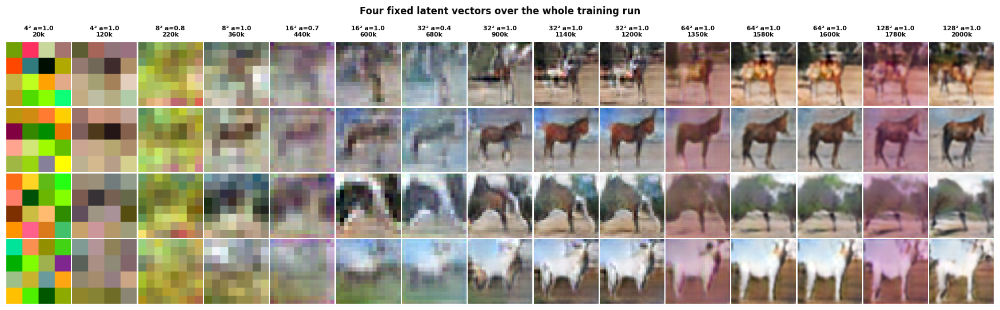

In [18]:
snaps = HIST["snaps"]
# pick ~14 moments spread over training, always including the end of every stage
ends = [max((s for s in snaps if s["res"] == r), key=lambda s: s["kimg"]) for r in CFG.schedule]
mid = [snaps[i] for i in np.linspace(0, len(snaps) - 1, 10).astype(int)]
sel = sorted({id(s): s for s in ends + mid}.values(), key=lambda s: s["kimg"])
ids = [0, 3, 6, 9]
fig, axes = plt.subplots(len(ids), len(sel), figsize=(len(sel) * 1.05, len(ids) * 1.18))
for j, s in enumerate(sel):
    imgs = F.interpolate(s["img"][ids].float(), size=128, mode="nearest").to(torch.uint8)
    for i in range(len(ids)):
        axes[i, j].imshow(imgs[i].permute(1, 2, 0).numpy()); axes[i, j].axis("off")
    axes[0, j].set_title(f'{s["res"]}² a={s["alpha"]:.1f}\n{s["kimg"]:.0f}k', fontsize=7)
plt.suptitle("Four fixed latent vectors over the whole training run", fontweight="bold", y=1.02)
plt.tight_layout(pad=0.2); savefig(fig, "fig07_fixed_z_timeline.png"); plt.show()

---
# 6. Generated images at every resolution

## 6.1 Saving the synthetic images

For every stage-end checkpoint the EMA generator draws **5 000** images (the evaluation set,
fixed seed). For the submission, **100 individual PNGs** and an 8 × 8 grid are written per
assignment resolution:

```
outputs/generated/032/  sample_000.png … sample_099.png, grid_8x8.png
outputs/generated/064/  …
outputs/generated/128/  …
```
The warm-up stages (4, 8, 16) get a grid only.

In [19]:
STAGES = list(CFG.schedule)                      # 4 ... 128
G_STAGE = load_generators("progan", STAGES, ema=True)
SAMPLES = {}
for r in STAGES:
    SAMPLES[r] = generate(G_STAGE[r], CFG.eval_n, res2step(r), seed=777)
    d = GEN / f"{r:03d}"; d.mkdir(exist_ok=True)
    if r >= 32:
        for i in range(100):
            Image.fromarray(SAMPLES[r][i].permute(1, 2, 0).numpy()).save(d / f"sample_{i:03d}.png")
    Image.fromarray(grid_image(SAMPLES[r][:64], 8)).save(d / "grid_8x8.png")
    print(f"res {r:3d}: generated {tuple(SAMPLES[r].shape)} -> {d.relative_to(ROOT)}")

res   4: generated (5000, 3, 4, 4) -> outputs\generated\004
res   8: generated (5000, 3, 8, 8) -> outputs\generated\008


res  16: generated (5000, 3, 16, 16) -> outputs\generated\016


res  32: generated (5000, 3, 32, 32) -> outputs\generated\032


res  64: generated (5000, 3, 64, 64) -> outputs\generated\064


res 128: generated (5000, 3, 128, 128) -> outputs\generated\128


## 6.2 Sample grids at 32 × 32, 64 × 64 and 128 × 128

The same 36 latent vectors (seed 777) are used in all three grids, so each tile shows the
*same* sample at the end of each stage. Each grid is shown at its native pixel size, enlarged for
display.

saved -> outputs\figures\fig08_samples_032.png


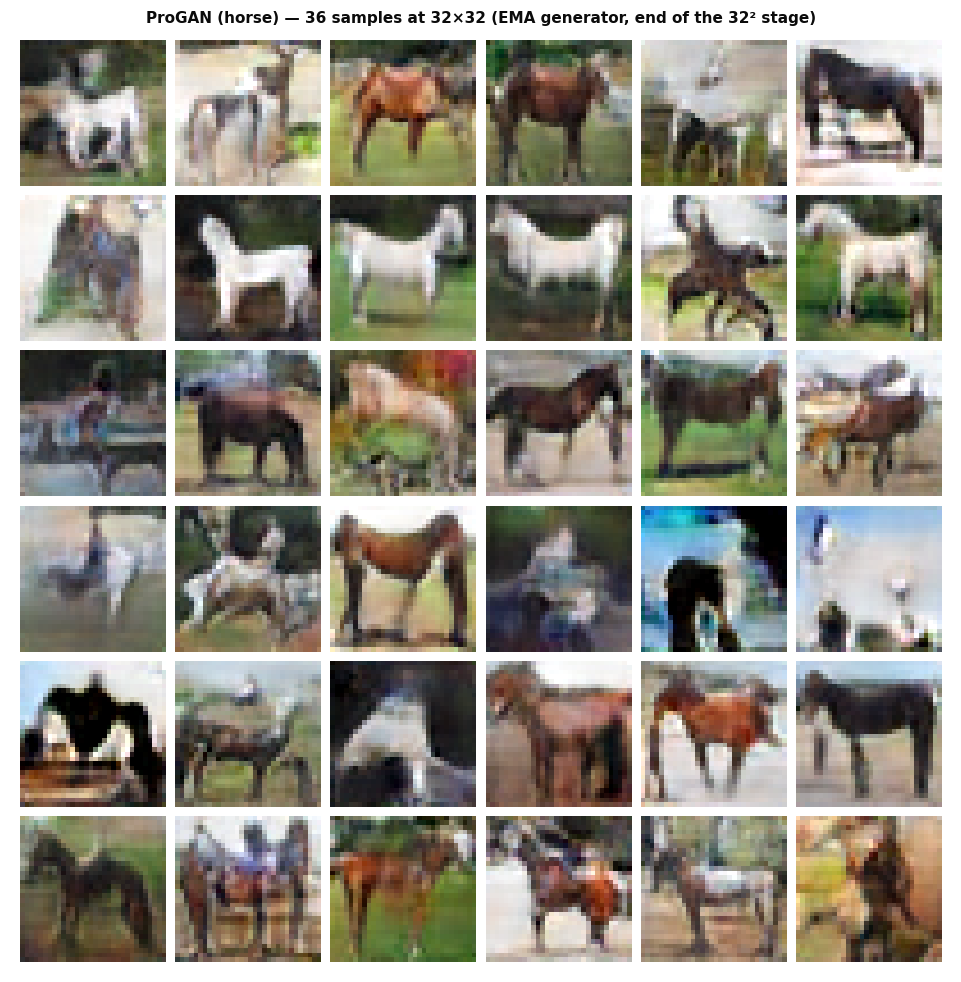

saved -> outputs\figures\fig08_samples_064.png


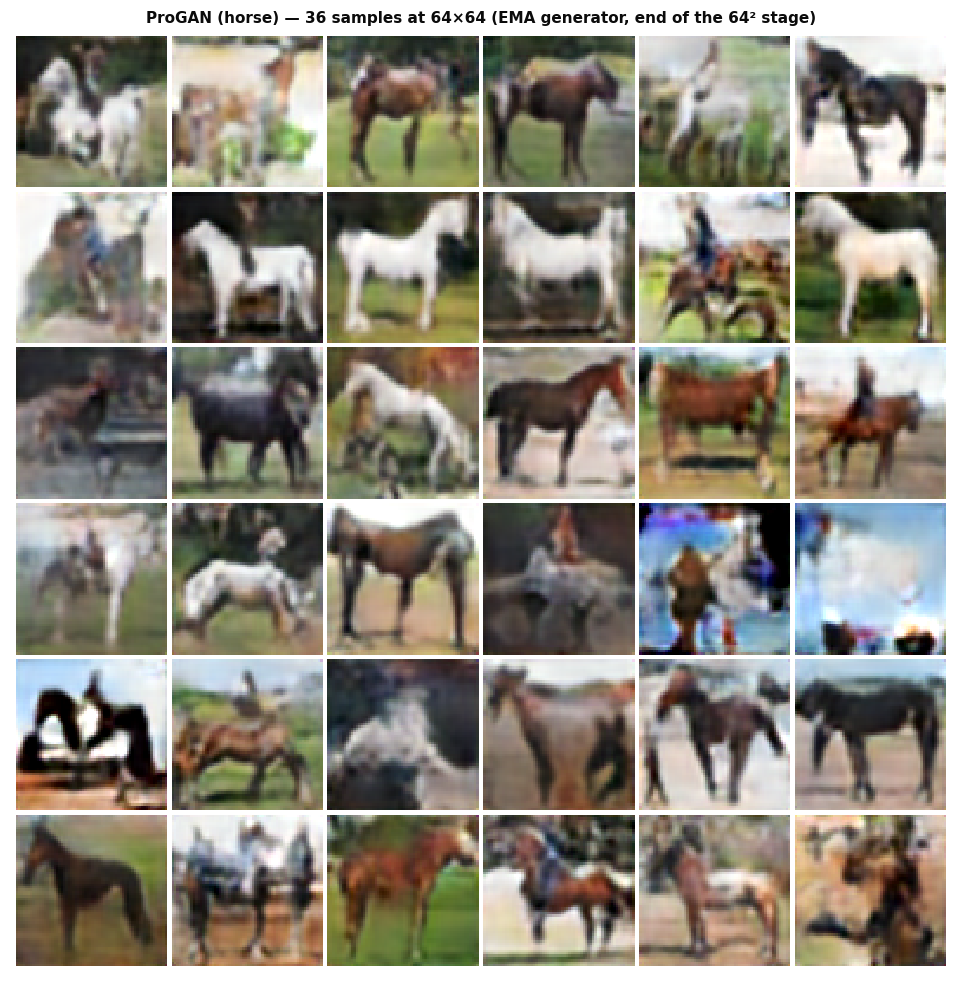

saved -> outputs\figures\fig08_samples_128.png


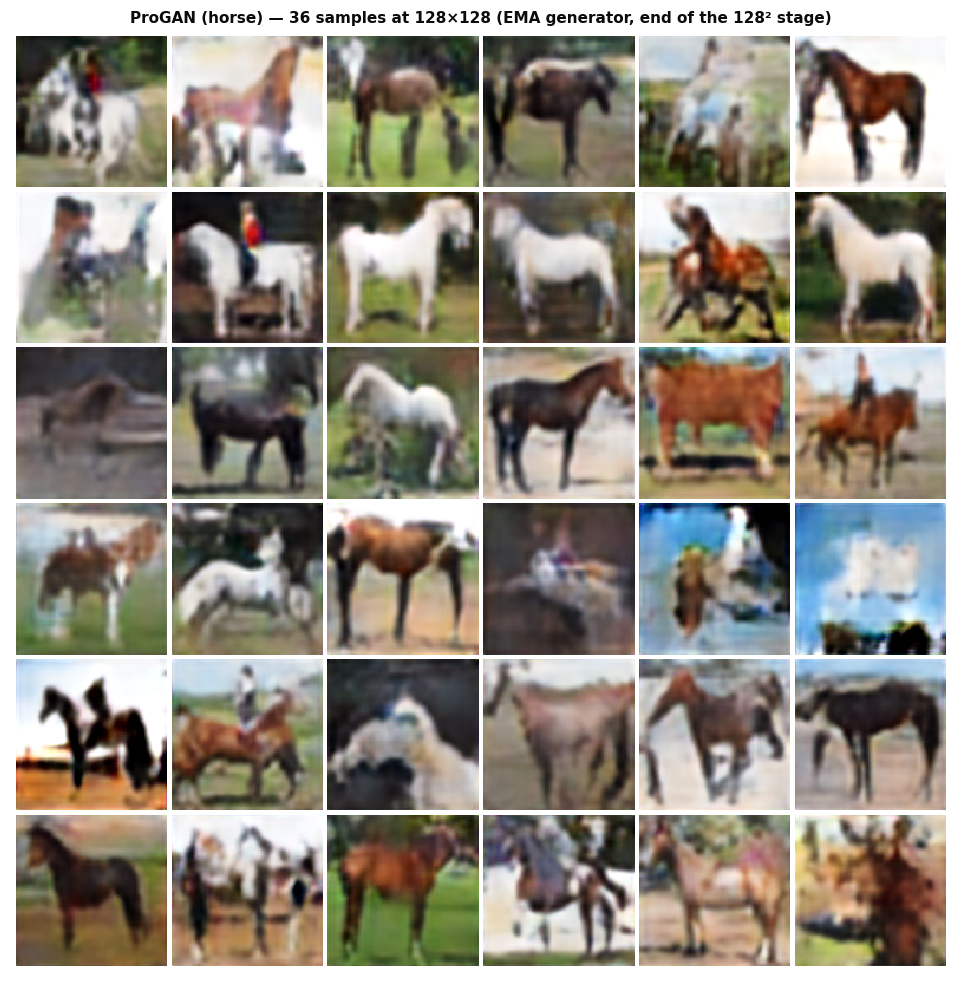

In [20]:
for r in (32, 64, 128):
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(grid_image(SAMPLES[r][:36], 6, pad=2 if r < 128 else 4), interpolation="nearest")
    ax.set_title(f"ProGAN ({CFG.class_name}) — 36 samples at {r}×{r} (EMA generator, end of the {r}² stage)")
    ax.axis("off"); plt.tight_layout(); savefig(fig, f"fig08_samples_{r:03d}.png"); plt.show()

## 6.3 One latent vector, six resolutions

Each column is one latent vector rendered by the stage-end generator of every resolution. Rows read
top to bottom as the network grows.

saved -> outputs\figures\fig09_progression_per_stage.png


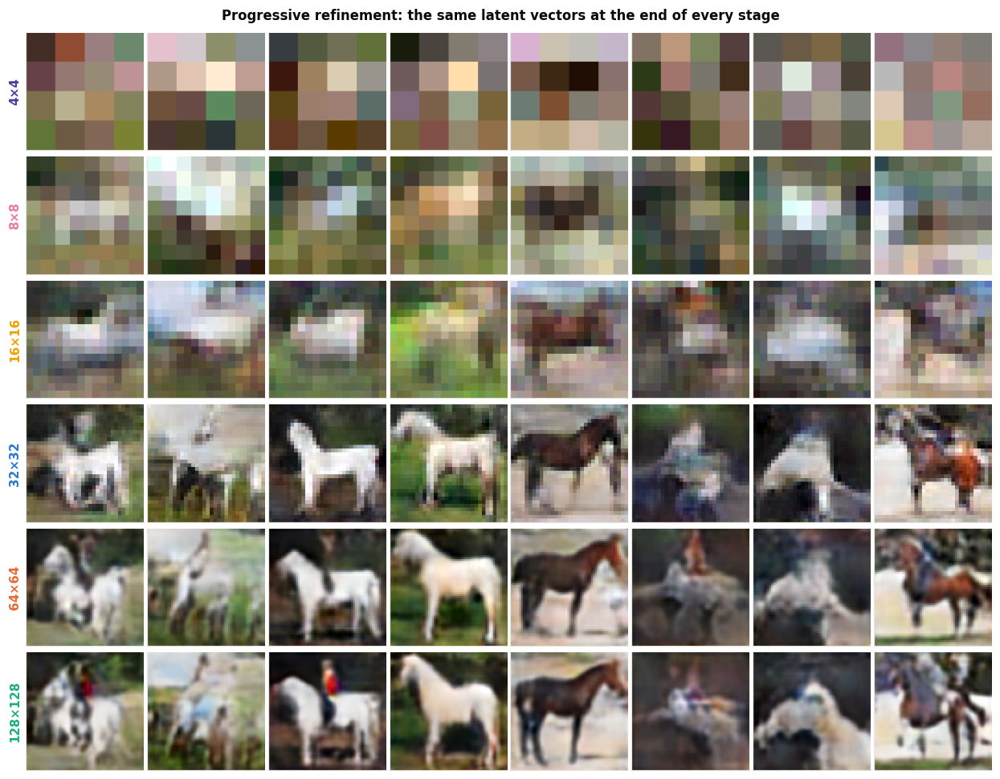

In [21]:
cols = [0, 4, 7, 11, 15, 21, 26, 33]
fig, axes = plt.subplots(len(STAGES), len(cols), figsize=(len(cols) * 1.4, len(STAGES) * 1.45))
for i, r in enumerate(STAGES):
    ims = F.interpolate(SAMPLES[r][cols].float(), size=128, mode="nearest").to(torch.uint8)
    for j in range(len(cols)):
        axes[i, j].imshow(ims[j].permute(1, 2, 0).numpy()); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    axes[i, 0].set_ylabel(f"{r}×{r}", fontsize=10, color=RES_COLOR[r], fontweight="bold")
plt.suptitle("Progressive refinement: the same latent vectors at the end of every stage", fontweight="bold", y=1.0)
plt.tight_layout(pad=0.3); savefig(fig, "fig09_progression_per_stage.png"); plt.show()

## 6.4 Real versus generated, side by side

The left half of each row is real (training set), the right half generated, at the same
resolution. The real 64 and 128 images are the bicubic-upsampled 32 × 32 originals, i.e.
exactly what the discriminator was shown.

saved -> outputs\figures\fig10_real_vs_generated.png


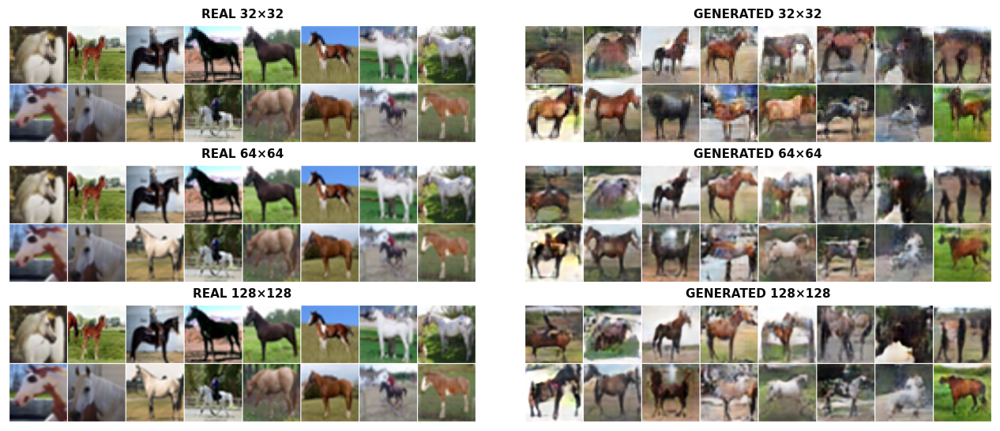

In [22]:
fig, axes = plt.subplots(3, 2, figsize=(12, 5.0))
ridx = np.random.default_rng(5).choice(len(X32), 16, replace=False)
for i, r in enumerate((32, 64, 128)):
    real = to_uint8(resize_real(X32[ridx], r))
    axes[i, 0].imshow(grid_image(real, 8, upscale_to=128)); axes[i, 0].set_title(f"REAL {r}×{r}")
    axes[i, 1].imshow(grid_image(SAMPLES[r][40:56], 8, upscale_to=128)); axes[i, 1].set_title(f"GENERATED {r}×{r}")
    axes[i, 0].set_ylabel(f"{r}×{r}")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); savefig(fig, "fig10_real_vs_generated.png"); plt.show()

## 6.5 What fade-in does

Fade-in can be visualised after training by evaluating a stage-end generator with `alpha < 1`:
`alpha = 0` is the previous resolution's `toRGB` output upsampled by nearest neighbour, `alpha = 1` is
the full new path. The 128-stage generator shows the 64 → 128 transition; the 64-stage generator
shows 32 → 64.

**Caveat when reading this figure.** After a fade-in ends, the old `toRGB_{s−1}` layer receives
no more gradient, but the convolution features it reads keep training. When it is re-activated
here with `alpha = 0` it is therefore out of calibration, which shows as over-saturated colour and
extra contrast. During training this path was only used while it was still calibrated. The figure
therefore shows the *mechanism* of the blend, not what the network produced in the middle of the
real fade-in. It also illustrates a general ProGAN property: the low-resolution outputs are scaffolding that is
abandoned once the next resolution takes over.

saved -> outputs\figures\fig11_fade_in.png


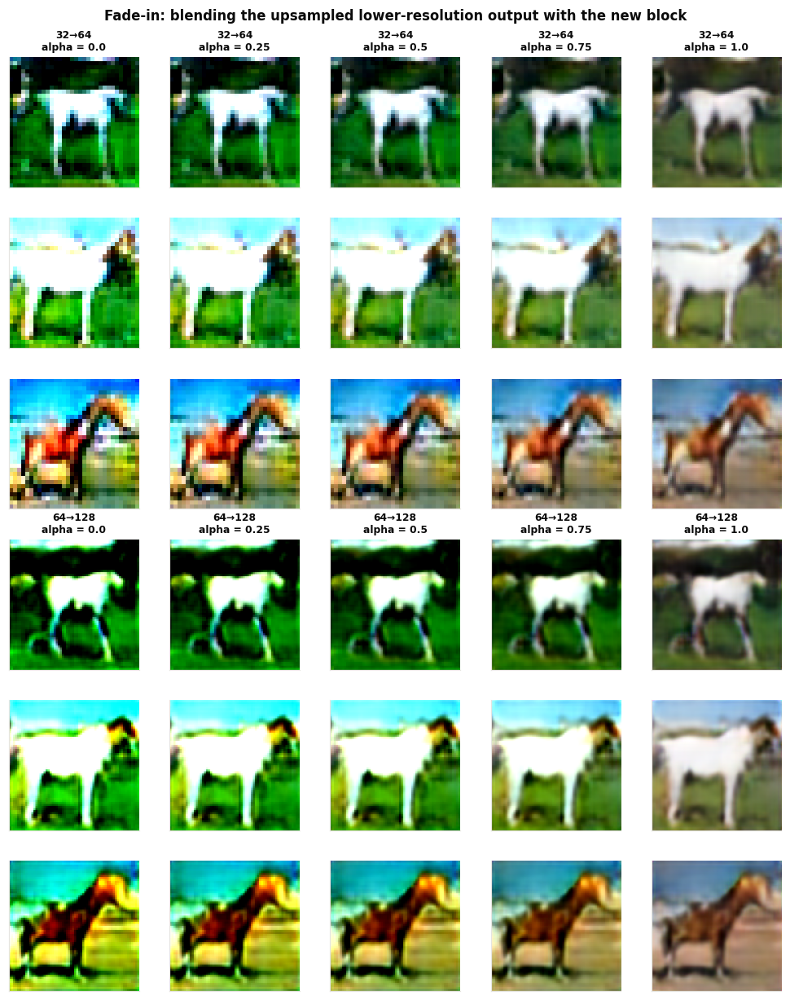

In [23]:
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]
zf = Z_FIXED[[1, 5, 12]]
fig, axes = plt.subplots(6, 5, figsize=(9, 11))
for blk, (r, ttl) in enumerate([(64, "32→64"), (128, "64→128")]):
    for j, a in enumerate(alphas):
        ims = generate(G_STAGE[r], 3, res2step(r), alpha=a, z=zf)
        for i in range(3):
            ax = axes[blk * 3 + i, j]
            ax.imshow(F.interpolate(ims[i:i + 1].float(), size=128, mode="nearest")[0].to(torch.uint8).permute(1, 2, 0).numpy())
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0: ax.set_title(f"{ttl}\nalpha = {a}", fontsize=8)
plt.suptitle("Fade-in: blending the upsampled lower-resolution output with the new block", fontweight="bold", y=1.0)
plt.tight_layout(pad=0.3); savefig(fig, "fig11_fade_in.png"); plt.show()

---
# 7. Quantitative evaluation

## 7.1 FID, KID, precision and recall at every stage

For every stage the EMA generator's 5 000 samples are compared with the 5 000 real training images
*at the same resolution*. Four reference lines put the numbers in context:

* **real test 1k** – the 1 000 held-out real horses vs. the training set: the score of a *perfect*
  generator at N = 1 000 (FID is biased by N, so the generated FID is also computed at N = 1 000
  for this row);
* **raw G** – the non-averaged generator, to measure what the EMA buys;
* **FID@32** – the 64 and 128 samples box-downsampled to 32 × 32 and compared with the native
  real 32 × 32 images. This answers *"did the content survive growing?"* independently of the
  upsampling filter.

In [24]:
G_RAW = load_generators("progan", (32, 64, 128), ema=False)
FAKE_FEATS, rows = {}, []
for r in (16, 32, 64, 128):
    f = inception_feats(SAMPLES[r]); FAKE_FEATS[r] = f
    fid = fid_from_stats(*feat_stats(f), *REAL_STATS[r])
    fid1k = fid_from_stats(*feat_stats(f[:1000]), *REAL_STATS[r])
    k_m, k_s = kid(f, REAL_FEATS[r])
    p, rc = precision_recall(REAL_FEATS[r], f)
    row = {"res": r, "FID-5k": fid, "FID-1k": fid1k, "KID×1e3": 1e3 * k_m, "KID std×1e3": 1e3 * k_s,
           "precision": p, "recall": rc}
    if r >= 32:
        f_raw = inception_feats(generate(G_RAW[r], CFG.eval_n, res2step(r), seed=777))
        row["FID-5k raw G"] = fid_from_stats(*feat_stats(f_raw), *REAL_STATS[r])
        f32 = inception_feats(F.avg_pool2d(SAMPLES[r].float(), r // 32).round().to(torch.uint8))
        row["FID@32 (downsampled)"] = fid_from_stats(*feat_stats(f32), *REAL_STATS[32])
        row["test-1k FID (floor)"] = fid_from_stats(*feat_stats(TEST_FEATS[r]), *REAL_STATS[r])
        row["test-1k KID×1e3 (floor)"] = 1e3 * kid(TEST_FEATS[r], REAL_FEATS[r])[0]
        pt, rt = precision_recall(REAL_FEATS[r], TEST_FEATS[r])
        row["test P/R (floor)"] = f"{pt:.3f} / {rt:.3f}"
    rows.append(row)
    print(f"res {r} done")
METRICS = pd.DataFrame(rows).set_index("res")
display(METRICS.round(3))
METRICS.to_csv(RES / "metrics_per_stage.csv")

res 16 done


res 32 done


res 64 done


res 128 done


,FID-5k,FID-1k,KID×1e3,KID std×1e3,precision,recall,FID-5k raw G,FID@32 (downsampled),test-1k FID (floor),test-1k KID×1e3 (floor),test P/R (floor)
res,,,,,,,,,,,
16,96.198,110.254,107.128,2.330,0.704,0.056,NaN,NaN,NaN,NaN,NaN
32,61.177,76.586,48.739,2.263,0.457,0.225,71.510,61.177,24.335,0.032,0.722 / 0.698
64,69.983,86.292,57.361,2.092,0.479,0.156,77.921,49.162,24.192,0.057,0.697 / 0.705
128,66.715,83.880,50.891,1.912,0.443,0.171,74.039,45.466,25.294,0.067,0.719 / 0.690


saved -> outputs\figures\fig12_metrics_per_stage.png


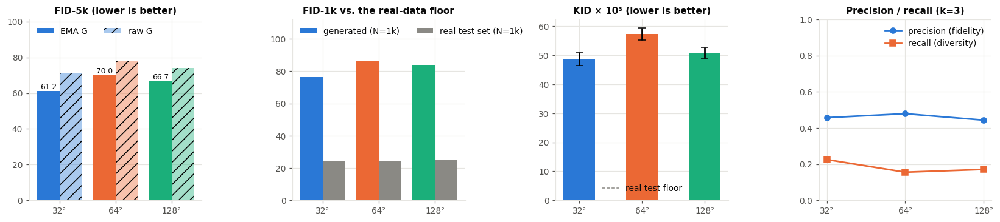

In [25]:
M = METRICS.loc[[32, 64, 128]]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
x = np.arange(3); lab = [f"{r}²" for r in M.index]; cols = [RES_COLOR[r] for r in M.index]
ax = axes[0]
ax.bar(x - 0.2, M["FID-5k"], 0.4, color=cols, label="EMA G")
ax.bar(x + 0.2, M["FID-5k raw G"], 0.4, color=cols, alpha=0.4, hatch="//", label="raw G")
ax.set_title("FID-5k (lower is better)"); ax.set_xticks(x, lab); ax.legend(loc="upper left", ncol=2)
ax.set_ylim(0, 1.3 * M["FID-5k raw G"].max())
for i, v in enumerate(M["FID-5k"]): ax.text(i - 0.2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
ax = axes[1]
ax.bar(x - 0.2, M["FID-1k"], 0.4, color=cols, label="generated (N=1k)")
ax.bar(x + 0.2, M["test-1k FID (floor)"], 0.4, color=INK3, label="real test set (N=1k)")
ax.set_title("FID-1k vs. the real-data floor"); ax.set_xticks(x, lab); ax.legend(loc="upper left", ncol=2)
ax.set_ylim(0, 1.3 * M["FID-1k"].max())
ax = axes[2]
ax.bar(x, M["KID×1e3"], 0.5, color=cols, yerr=M["KID std×1e3"], capsize=4)
ax.axhline(M["test-1k KID×1e3 (floor)"].mean(), color=INK3, ls="--", lw=1, label="real test floor")
ax.set_title("KID × 10³ (lower is better)"); ax.set_xticks(x, lab); ax.legend()
ax = axes[3]
ax.plot(lab, M["precision"], "-o", color=PALETTE[0], label="precision (fidelity)")
ax.plot(lab, M["recall"], "-s", color=PALETTE[1], label="recall (diversity)")
ax.set_ylim(0, 1); ax.set_title("Precision / recall (k=3)"); ax.legend()
plt.tight_layout(); savefig(fig, "fig12_metrics_per_stage.png"); plt.show()

## 7.2 Class fidelity: does a CIFAR-10 classifier see horses?

FID measures distribution distance but says nothing explicit about the *class*. A ResNet-18
(CIFAR variant: 3 × 3 stem, no max-pool) is trained on all ten CIFAR-10 classes and then asked to
label the generated images (64/128 samples are area-downsampled to 32 × 32, the classifier's
native size). The **horse rate** is the fraction labelled `horse`. The classifier's recall on the
real test horses gives the ceiling.

In [26]:
def make_classifier():
    m = torchvision.models.resnet18(num_classes=10)
    m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False); m.maxpool = nn.Identity()
    return m.to(DEV).to(memory_format=torch.channels_last)

MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=DEV).view(1, 3, 1, 1)
STD  = torch.tensor([0.2470, 0.2435, 0.2616], device=DEV).view(1, 3, 1, 1)
def cls_in(x_u8): return ((x_u8.to(DEV).float() / 255) - MEAN) / STD

CLF_PATH = CKPT / "cifar10_resnet18.pt"
clf = make_classifier()
Xa = torch.from_numpy(Xtr_all).to(DEV); ya = torch.from_numpy(ytr_all).long().to(DEV)
Xt = torch.from_numpy(Xte_all).to(DEV); yt = torch.from_numpy(yte_all).long().to(DEV)
if CLF_PATH.exists():
    clf.load_state_dict(torch.load(CLF_PATH, map_location=DEV)); print("loaded", CLF_PATH.name)
else:
    set_seed(0)
    EP, BS = 18, 512
    opt = torch.optim.SGD(clf.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 0.2, total_steps=EP * math.ceil(len(Xa) / BS), pct_start=0.25)
    t = time.time()
    for ep in range(EP):
        clf.train(); perm = torch.randperm(len(Xa), device=DEV)
        for i in range(0, len(Xa), BS):
            b = perm[i:i + BS]; x = cls_in(Xa[b])
            x = F.pad(x, (4, 4, 4, 4), mode="reflect")                       # random crop + flip on GPU
            dx, dy = np.random.randint(0, 9, 2); x = x[:, :, dy:dy + 32, dx:dx + 32]
            x = torch.where(torch.rand(len(b), 1, 1, 1, device=DEV) < 0.5, x.flip(3), x)
            with torch.autocast("cuda", torch.bfloat16):
                loss = F.cross_entropy(clf(x.contiguous(memory_format=torch.channels_last)), ya[b], label_smoothing=0.1)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        if ep % 3 == 2 or ep == EP - 1:
            print(f"epoch {ep + 1:2d}  loss {loss.item():.3f}  ({time.time() - t:.0f}s)")
    torch.save(clf.state_dict(), CLF_PATH)
clf.eval()

@torch.no_grad()
def classify(x_u8, bs=1000):
    if x_u8.shape[-1] != 32:
        x_u8 = F.interpolate(x_u8.float(), size=32, mode="area").round().to(torch.uint8)
    out = []
    for i in range(0, len(x_u8), bs):
        with torch.autocast("cuda", torch.bfloat16):
            out.append(clf(cls_in(x_u8[i:i + bs]).contiguous(memory_format=torch.channels_last)).float().softmax(1).cpu())
    return torch.cat(out)

p_test = classify(Xt.cpu())
acc = (p_test.argmax(1).numpy() == yte_all).mean()
real_rate = (p_test[yte_all == CLS].argmax(1) == CLS).float().mean().item()
print(f"classifier CIFAR-10 test accuracy: {acc:.4f}   recall on real test {CFG.class_name}s: {real_rate:.4f}")

loaded cifar10_resnet18.pt


classifier CIFAR-10 test accuracy: 0.9236   recall on real test horses: 0.9400


                   horse rate  mean P(horse)
set                                         
real test horses       0.9400         0.8342
generated 4×4          0.0000         0.0104
generated 8×8          0.0040         0.0355
generated 16×16        0.0208         0.0507
generated 32×32        0.7546         0.6533
generated 64×64        0.8036         0.6987
generated 128×128      0.8414         0.7336


saved -> outputs\figures\fig13_classifier_fidelity.png


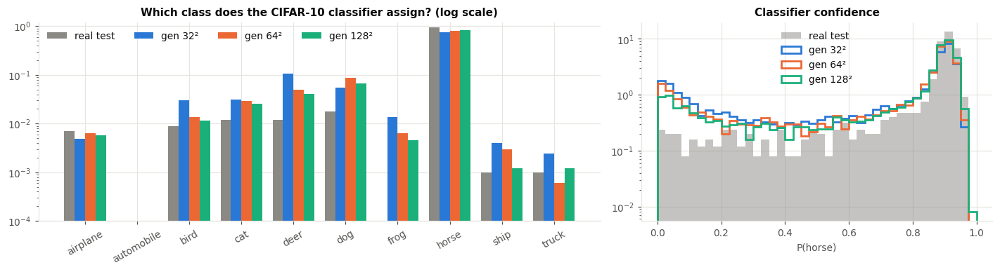

In [27]:
PROBS = {r: classify(SAMPLES[r]) for r in STAGES}
crow = [{"set": f"real test {CFG.class_name}s", "horse rate": real_rate,
         "mean P(horse)": p_test[yte_all == CLS][:, CLS].mean().item()}]
for r in STAGES:
    crow.append({"set": f"generated {r}×{r}", "horse rate": (PROBS[r].argmax(1) == CLS).float().mean().item(),
                 "mean P(horse)": PROBS[r][:, CLS].mean().item()})
# baseline: what does the classifier say about random-noise-ish images? (Gaussian blobs)
CLS_DF = pd.DataFrame(crow).set_index("set")
print(CLS_DF.round(4).to_string()); CLS_DF.to_csv(RES / "classifier_fidelity.csv")
METRICS["horse rate"] = [CLS_DF.loc[f"generated {r}×{r}", "horse rate"] for r in METRICS.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]; w = 0.2
dists = {"real test": np.bincount(p_test[yte_all == CLS].argmax(1).numpy(), minlength=10) / (yte_all == CLS).sum()}
for r in (32, 64, 128):
    dists[f"gen {r}²"] = np.bincount(PROBS[r].argmax(1).numpy(), minlength=10) / len(PROBS[r])
for i, (k, v) in enumerate(dists.items()):
    ax.bar(np.arange(10) + (i - 1.5) * w, v, w, label=k, color=[INK3, RES_COLOR[32], RES_COLOR[64], RES_COLOR[128]][i])
ax.set_xticks(range(10), CLASSES, rotation=30); ax.set_yscale("log"); ax.set_ylim(1e-4, 1.2)
ax.set_title("Which class does the CIFAR-10 classifier assign? (log scale)"); ax.legend(ncol=4)
ax = axes[1]
bins = np.linspace(0, 1, 41)
ax.hist(p_test[yte_all == CLS][:, CLS].numpy(), bins, density=True, color=INK3, alpha=0.5, label="real test")
for r in (32, 64, 128):
    ax.hist(PROBS[r][:, CLS].numpy(), bins, density=True, histtype="step", lw=1.8, color=RES_COLOR[r], label=f"gen {r}²")
ax.set_yscale("log"); ax.set_xlabel(f"P({CFG.class_name})"); ax.set_title("Classifier confidence"); ax.legend()
plt.tight_layout(); savefig(fig, "fig13_classifier_fidelity.png"); plt.show()

## 7.3 Does the 128 × 128 stage add anything beyond upsampling?

The real 128 × 128 images contain no information that the 32 × 32 images do not, so a fair question is
whether the extra stages beat the trivial alternative: **take the 32-stage generator's output and
bicubically upsample it**. This baseline is compared with the 64 and 128 generators on the same
metrics.

 res                 method  FID-5k  KID×1e3  precision  recall
  64 G32 + bicubic upsample  76.304   63.052      0.490   0.179
  64       ProGAN 64² stage  69.983   57.361      0.479   0.156
 128 G32 + bicubic upsample  85.393   68.566      0.541   0.155
 128      ProGAN 128² stage  66.715   50.891      0.443   0.171


saved -> outputs\figures\fig14_upsample_baseline.png


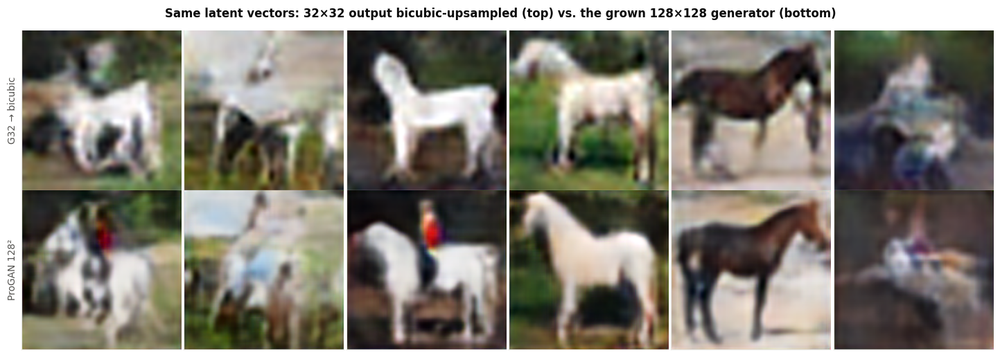

In [28]:
rows = []
for r in (64, 128):
    up = to_uint8(F.interpolate(SAMPLES[32].float().div(127.5).sub(1), size=r, mode="bicubic", align_corners=False))
    f_up = inception_feats(up)
    p, rc = precision_recall(REAL_FEATS[r], f_up)
    rows.append({"res": r, "method": "G32 + bicubic upsample", "FID-5k": fid_from_stats(*feat_stats(f_up), *REAL_STATS[r]),
                 "KID×1e3": 1e3 * kid(f_up, REAL_FEATS[r])[0], "precision": p, "recall": rc})
    rows.append({"res": r, "method": f"ProGAN {r}² stage", "FID-5k": METRICS.loc[r, "FID-5k"],
                 "KID×1e3": METRICS.loc[r, "KID×1e3"], "precision": METRICS.loc[r, "precision"], "recall": METRICS.loc[r, "recall"]})
    UPS = up if r == 128 else None
UPS_DF = pd.DataFrame(rows); print(UPS_DF.round(3).to_string(index=False)); UPS_DF.to_csv(RES / "upsample_baseline.csv", index=False)

fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for j, i in enumerate([0, 4, 7, 11, 15, 21]):
    axes[0, j].imshow(UPS[i].permute(1, 2, 0).numpy()); axes[1, j].imshow(SAMPLES[128][i].permute(1, 2, 0).numpy())
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("G32 → bicubic"); axes[1, 0].set_ylabel("ProGAN 128²")
plt.suptitle("Same latent vectors: 32×32 output bicubic-upsampled (top) vs. the grown 128×128 generator (bottom)",
             fontweight="bold", y=1.0)
plt.tight_layout(pad=0.3); savefig(fig, "fig14_upsample_baseline.png"); plt.show()

---
# 8. Deeper inspection

## 8.1 Memorisation check: nearest training neighbours

With only 5 000 training images (10 000 with flips) and hundreds of passes over them, a GAN
could simply reproduce training images. Two checks:

1. **Visual:** for generated samples, the three closest training images (Inception-feature
   L2 distance, flips included).
2. **Statistical:** the distribution of nearest-training-neighbour distances of generated
   samples is compared with that of the **held-out test horses**. A memorising generator would sit
   *much closer* to the training set than unseen real images do.

                   set  median NN distance  5th percentile  min
   generated 128² (2k)               14.21            9.36 6.93
real test (1k, unseen)               11.28            7.21 3.34
saved -> outputs\figures\fig15_nn_distance.png


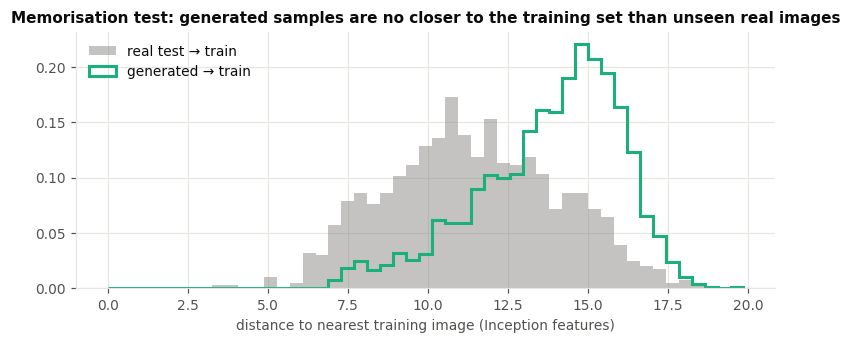

saved -> outputs\figures\fig16_nearest_neighbours.png


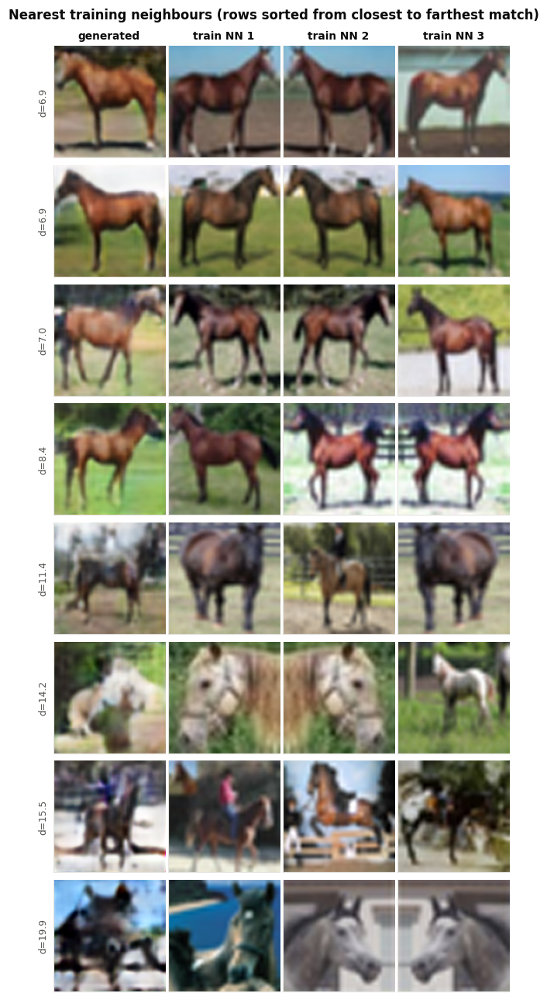

In [29]:
r = 128
tr_f = torch.from_numpy(np.concatenate([REAL_FEATS[r], inception_feats(resize_real(X32.flip(3), r))])).float().to(DEV)
def nn_dist(f, k=1):
    d = torch.cdist(torch.from_numpy(f).float().to(DEV), tr_f)
    v, i = d.topk(k, largest=False); return v.cpu().numpy(), i.cpu().numpy()
d_gen, i_gen = nn_dist(FAKE_FEATS[r][:2000], 3)
d_test, _ = nn_dist(TEST_FEATS[r], 1)
NN_DF = pd.DataFrame({"set": ["generated 128² (2k)", "real test (1k, unseen)"],
                      "median NN distance": [np.median(d_gen[:, 0]), np.median(d_test[:, 0])],
                      "5th percentile": [np.percentile(d_gen[:, 0], 5), np.percentile(d_test[:, 0], 5)],
                      "min": [d_gen[:, 0].min(), d_test[:, 0].min()]})
print(NN_DF.round(2).to_string(index=False)); NN_DF.to_csv(RES / "memorisation.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, max(d_gen[:, 0].max(), d_test[:, 0].max()), 50)
ax.hist(d_test[:, 0], bins, density=True, color=INK3, alpha=0.5, label="real test → train")
ax.hist(d_gen[:, 0], bins, density=True, histtype="step", lw=2, color=RES_COLOR[128], label="generated → train")
ax.set_xlabel("distance to nearest training image (Inception features)"); ax.legend()
ax.set_title("Memorisation test: generated samples are no closer to the training set than unseen real images")
plt.tight_layout(); savefig(fig, "fig15_nn_distance.png"); plt.show()

X_aug = torch.cat([X32, X32.flip(3)])
pick = np.argsort(d_gen[:, 0])[[0, 1, 2, 50, 300, 1000, 1500, 1999]]     # closest ... typical ... farthest
fig, axes = plt.subplots(len(pick), 4, figsize=(5.6, len(pick) * 1.45))
for i, g in enumerate(pick):
    axes[i, 0].imshow(SAMPLES[128][g].permute(1, 2, 0).numpy())
    axes[i, 0].set_ylabel(f"d={d_gen[g, 0]:.1f}", fontsize=8)
    for j in range(3):
        axes[i, j + 1].imshow(to_uint8(resize_real(X_aug[i_gen[g, j]][None], 128))[0].permute(1, 2, 0).numpy())
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_title("generated", fontsize=9)
for j in range(3): axes[0, j + 1].set_title(f"train NN {j + 1}", fontsize=9)
plt.suptitle("Nearest training neighbours (rows sorted from closest to farthest match)", fontweight="bold", y=1.0)
plt.tight_layout(pad=0.3); savefig(fig, "fig16_nearest_neighbours.png"); plt.show()

## 8.2 Latent-space interpolation

Spherical interpolation (slerp) between pairs of latent vectors at 128 × 128. Smooth transitions,
with no abrupt jumps and no stretches of identical images, indicate that the generator has learned a continuous
mapping rather than a lookup table of memorised images.

saved -> outputs\figures\fig17_interpolation.png


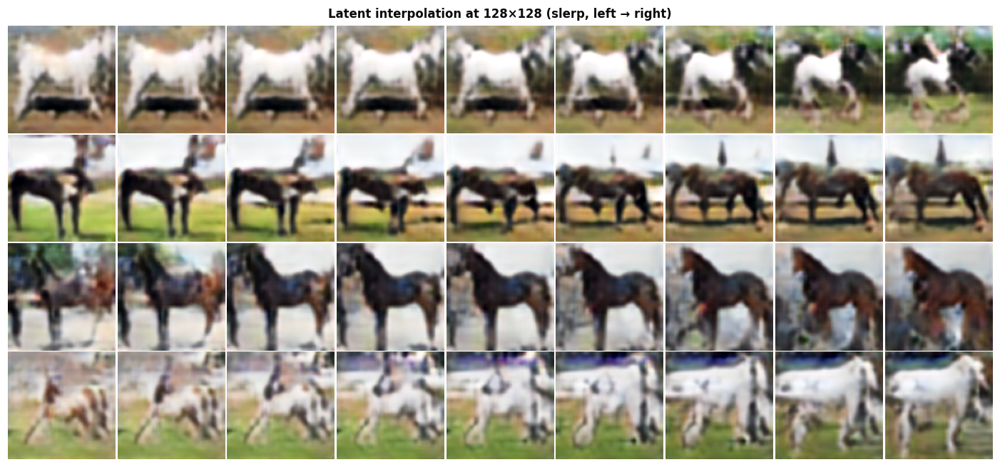

In [30]:
def slerp(a, b, t):
    a_n, b_n = a / a.norm(), b / b.norm()
    om = torch.acos((a_n * b_n).sum().clamp(-1, 1))
    return (torch.sin((1 - t) * om) * a + torch.sin(t * om) * b) / torch.sin(om)
g = torch.Generator(device=DEV).manual_seed(31)
n_steps, n_rows = 9, 4
fig, axes = plt.subplots(n_rows, n_steps, figsize=(n_steps * 1.4, n_rows * 1.45))
for i in range(n_rows):
    a, b = torch.randn(CFG.z_dim, device=DEV, generator=g), torch.randn(CFG.z_dim, device=DEV, generator=g)
    zs = torch.stack([slerp(a, b, t) for t in torch.linspace(0, 1, n_steps)])
    ims = generate(G_STAGE[128], n_steps, res2step(128), z=zs)
    for j in range(n_steps):
        axes[i, j].imshow(ims[j].permute(1, 2, 0).numpy()); axes[i, j].axis("off")
plt.suptitle("Latent interpolation at 128×128 (slerp, left → right)", fontweight="bold", y=1.0)
plt.tight_layout(pad=0.2); savefig(fig, "fig17_interpolation.png"); plt.show()

## 8.3 Frequency content

The azimuthally averaged power spectrum of the grey-level images compares how much energy real and
generated images carry at each spatial frequency. At 128 × 128 the real spectrum falls off
steeply above the original 32 × 32 Nyquist limit (0.125 cycles/pixel), because bicubic
upsampling cannot create detail. Any generated energy above that line is detail that does not exist
in the training data (GAN "checkerboard" artefacts usually show up there).

saved -> outputs\figures\fig18_power_spectrum.png


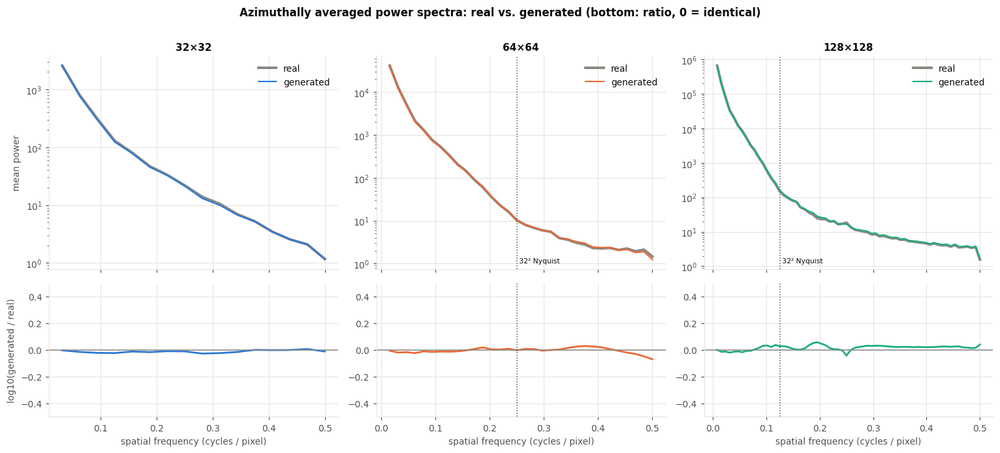

 res    high band  log10(gen/real) mean in high band  log10(gen/real) mean in low band
  32 > 0.250 c/px                             -0.009                            -0.014
  64 > 0.250 c/px                             -0.003                            -0.006
 128 > 0.125 c/px                              0.021                             0.004


In [31]:
def radial_spectrum(x_u8, n=2000):
    x = x_u8[:n].float().to(DEV)
    g = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]) / 255
    g = g - g.mean(dim=(1, 2), keepdim=True)
    P = torch.fft.fftshift(torch.fft.fft2(g).abs().pow(2), dim=(-2, -1)).mean(0)
    h = P.shape[0]; yy, xx = torch.meshgrid(torch.arange(h, device=DEV), torch.arange(h, device=DEV), indexing="ij")
    rr = ((yy - h // 2) ** 2 + (xx - h // 2) ** 2).sqrt().round().long()
    prof = torch.bincount(rr.flatten(), P.flatten()) / torch.bincount(rr.flatten())
    f = torch.arange(len(prof)) / h
    k = f <= 0.5
    return f[k].numpy(), prof[k].cpu().numpy()

fig, axes = plt.subplots(2, 3, figsize=(14, 6.2), sharex="col", gridspec_kw={"height_ratios": [1.6, 1]})
SPEC = {}
for j, r in enumerate((32, 64, 128)):
    fr, pr = radial_spectrum(to_uint8(resize_real(X32, r)))
    fg, pg = radial_spectrum(SAMPLES[r])
    SPEC[r] = (fr, pr, pg)
    k = fr > 0                                          # the DC bin is ~0 after mean removal
    ax = axes[0, j]
    ax.semilogy(fr[k], pr[k], color=INK3, lw=2.6, label="real")
    ax.semilogy(fg[k], pg[k], color=RES_COLOR[r], lw=1.4, label="generated")
    ax.set_title(f"{r}×{r}"); ax.legend()
    ax = axes[1, j]
    ax.plot(fr[k], np.log10(pg[k] / pr[k]), color=RES_COLOR[r])
    ax.axhline(0, color=INK3, lw=1)
    ax.set_ylim(-0.5, 0.5); ax.set_xlabel("spatial frequency (cycles / pixel)")
    for a in axes[:, j]:
        if r > 32: a.axvline(16 / r, color=INK2, ls=":", lw=1)
    if r > 32: axes[0, j].text(16 / r, 0.03, " 32² Nyquist", transform=axes[0, j].get_xaxis_transform(), fontsize=7)
axes[0, 0].set_ylabel("mean power"); axes[1, 0].set_ylabel("log10(generated / real)")
plt.suptitle("Azimuthally averaged power spectra: real vs. generated (bottom: ratio, 0 = identical)", fontweight="bold", y=1.01)
plt.tight_layout(); savefig(fig, "fig18_power_spectrum.png"); plt.show()

rows = []
for r, (f, pr, pg) in SPEC.items():
    band = f > (16 / r if r > 32 else 0.25)
    rows.append({"res": r, "high band": f"> {16 / r if r > 32 else 0.25:.3f} c/px",
                 "log10(gen/real) mean in high band": np.log10(pg[band] / pr[band]).mean(),
                 "log10(gen/real) mean in low band": np.log10(pg[~band][1:] / pr[~band][1:]).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
pd.DataFrame(rows).to_csv(RES / "spectrum.csv", index=False)

## 8.4 Best and worst samples

The 5 000 samples at 128 × 128 are ranked by the classifier's P(horse). The top rows are the most
convincing horses; the bottom rows are the generator's typical failure modes.

saved ->

 outputs\figures\fig19_best_worst.png


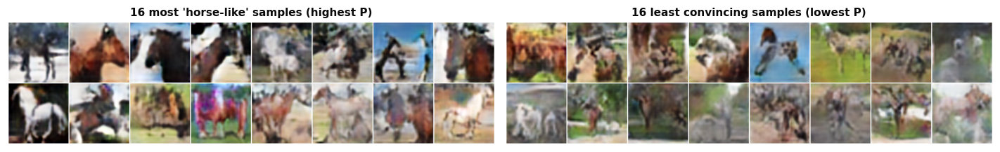

classifier labels of the 16 worst samples: {'dog': 8, 'deer': 4, 'cat': 2, 'bird': 2}
labels of all 5000 generated 128² samples: {'horse': 4207, 'dog': 338, 'deer': 204, 'cat': 129, 'bird': 58, 'airplane': 29, 'frog': 23, 'ship': 6, 'truck': 6}


In [32]:
order = PROBS[128][:, CLS].argsort(descending=True)
best, worst = order[:16], order[-16:]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].imshow(grid_image(SAMPLES[128][best], 8)); axes[0].set_title(f"16 most '{CFG.class_name}-like' samples (highest P)")
axes[1].imshow(grid_image(SAMPLES[128][worst], 8)); axes[1].set_title("16 least convincing samples (lowest P)")
for a in axes: a.axis("off")
plt.tight_layout(); savefig(fig, "fig19_best_worst.png"); plt.show()
wl = pd.Series(PROBS[128][worst].argmax(1).numpy()).map(lambda c: CLASSES[c]).value_counts()
print("classifier labels of the 16 worst samples:", wl.to_dict())
fail = pd.Series(PROBS[128].argmax(1).numpy()).map(lambda c: CLASSES[c]).value_counts()
print("labels of all 5000 generated 128² samples:", fail.to_dict())

---
# 9. Ablation: progressive growing vs. training directly at full resolution

## 9.1 At the native resolution: direct 32 × 32 vs. progressive 4 → 32

The central claim of ProGAN is that growing is **faster and more stable** than training the full
network from the start. To test it at affordable cost, the same 32 × 32 network (identical
layers, loss, optimiser, batch, EMA, data) is trained **directly at 32 × 32 from step 0**, for
the same number of images that the progressive run showed up to the end of its 32 × 32 stage
(1 200 kimg). Both runs are compared against images shown and against wall-clock time.

In [33]:
DIRECT_KIMG = sum(sum(CFG.schedule[r]) for r in (4, 8, 16, 32))
direct_sched = {32: (0, DIRECT_KIMG)}
t = time.time()
HIST_D = train_gan(direct_sched, "direct32")
print(f"cell time: {(time.time() - t) / 60:.1f} min")

G_direct = load_generators("direct32", [32])[32]
S_direct = generate(G_direct, CFG.eval_n, res2step(32), seed=777)
f_d = inception_feats(S_direct)
p_d, r_d = precision_recall(REAL_FEATS[32], f_d)
prog_time32 = sum(HIST["stage_time"][r] for r in (4, 8, 16, 32))
ABL = pd.DataFrame([
    {"run": "progressive 4→32", "kimg": DIRECT_KIMG, "wall time (min)": prog_time32 / 60,
     "FID-5k": METRICS.loc[32, "FID-5k"], "KID×1e3": METRICS.loc[32, "KID×1e3"],
     "precision": METRICS.loc[32, "precision"], "recall": METRICS.loc[32, "recall"],
     "horse rate": CLS_DF.loc["generated 32×32", "horse rate"]},
    {"run": "direct 32 (no growing)", "kimg": DIRECT_KIMG, "wall time (min)": HIST_D["stage_time"][32] / 60,
     "FID-5k": fid_from_stats(*feat_stats(f_d), *REAL_STATS[32]), "KID×1e3": 1e3 * kid(f_d, REAL_FEATS[32])[0],
     "precision": p_d, "recall": r_d, "horse rate": (classify(S_direct).argmax(1) == CLS).float().mean().item()}]).set_index("run")
print(ABL.round(3).to_string()); ABL.to_csv(RES / "ablation_progressive_vs_direct.csv")

[direct32] found finished run -> loaded direct32_res032.pt
cell time: 0.0 min


                        kimg  wall time (min)  FID-5k  KID×1e3  precision  recall  horse rate
run                                                                                          
progressive 4→32        1200           13.885  61.177   48.739      0.457   0.225       0.755
direct 32 (no growing)  1200           21.095  47.483   31.148      0.489   0.250       0.799


saved -> outputs\figures\fig20_ablation_curves.png


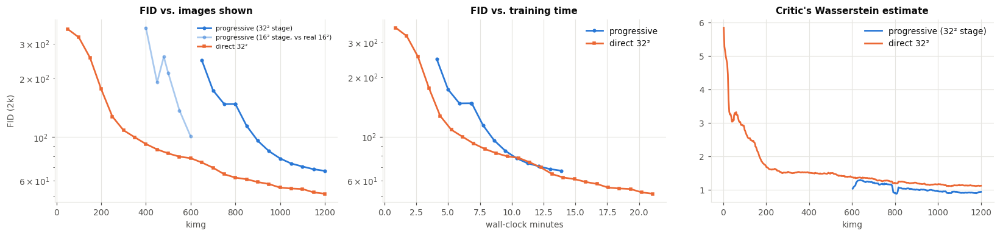

saved -> outputs\figures\fig21_ablation_samples.png


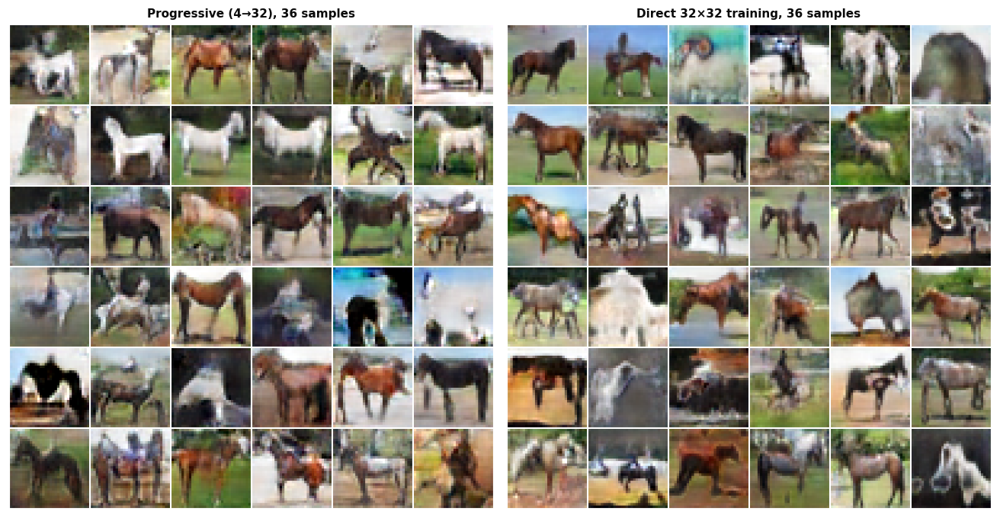

In [34]:
fd = pd.DataFrame(HIST_D["fid"]); ld = pd.DataFrame(HIST_D["log"])
fp = fidlog[fidlog.res <= 32]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
ax = axes[0]
ax.plot(fp[fp.res == 32]["kimg"], fp[fp.res == 32]["fid"], "-o", ms=3, color=PALETTE[0], label="progressive (32² stage)")
ax.plot(fp[fp.res == 16]["kimg"], fp[fp.res == 16]["fid"], "-o", ms=3, color=PALETTE[0], alpha=0.4, label="progressive (16² stage, vs real 16²)")
ax.plot(fd["kimg"], fd["fid"], "-s", ms=3, color=PALETTE[1], label="direct 32²")
ax.set_yscale("log"); ax.set_xlabel("kimg"); ax.set_ylabel("FID (2k)"); ax.set_title("FID vs. images shown"); ax.legend(fontsize=7)
ax = axes[1]
ax.plot(fp[fp.res == 32]["time"] / 60, fp[fp.res == 32]["fid"], "-o", ms=3, color=PALETTE[0], label="progressive")
ax.plot(fd["time"] / 60, fd["fid"], "-s", ms=3, color=PALETTE[1], label="direct 32²")
ax.set_yscale("log"); ax.set_xlabel("wall-clock minutes"); ax.set_title("FID vs. training time"); ax.legend()
ax = axes[2]
lp = log[log.res == 32]
ax.plot(lp["kimg"], sm(lp["w_dist"]), color=PALETTE[0], label="progressive (32² stage)")
ax.plot(ld["kimg"], sm(ld["w_dist"]), color=PALETTE[1], label="direct 32²")
ax.set_xlabel("kimg"); ax.set_title("Critic's Wasserstein estimate"); ax.legend()
plt.tight_layout(); savefig(fig, "fig20_ablation_curves.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
axes[0].imshow(grid_image(SAMPLES[32][:36], 6, upscale_to=96)); axes[0].set_title("Progressive (4→32), 36 samples")
axes[1].imshow(grid_image(S_direct[:36], 6, upscale_to=96)); axes[1].set_title("Direct 32×32 training, 36 samples")
for a in axes: a.axis("off")
plt.tight_layout(); savefig(fig, "fig21_ablation_samples.png"); plt.show()

## 9.2 At the target resolution: direct 128 × 128 vs. progressive, equal wall-clock budget

At 32 × 32 the networks are shallow and WGAN-GP trains stably without help, so the 32 × 32 test
cannot show ProGAN's real advantage. ProGAN claims its benefit at *high* resolution. Here the
full 128 × 128 network (all six blocks, `alpha = 1` from the first step) is trained from scratch for the
**same wall-clock time as the whole progressive run** (4 → 128). The image budget is computed from
the measured progressive time and the measured 128 × 128 throughput, so both runs get the same
amount of GPU time.

In [35]:
prog_total_s = sum(HIST["stage_time"].values())
thr128 = stage_time.loc[128, "img/s"]
DIRECT128_KIMG = int(prog_total_s * thr128 / 1000 / 10) * 10
print(f"progressive total {prog_total_s / 60:.1f} min x {thr128:.0f} img/s at 128 -> {DIRECT128_KIMG} kimg budget")
t = time.time()
HIST_D128 = train_gan({128: (0, DIRECT128_KIMG)}, "direct128")
print(f"cell time: {(time.time() - t) / 60:.1f} min")

G_d128 = load_generators("direct128", [128])[128]
S_d128 = generate(G_d128, CFG.eval_n, res2step(128), seed=777)
f_d128 = inception_feats(S_d128)
p_d128, r_d128 = precision_recall(REAL_FEATS[128], f_d128)
f_d128_32 = inception_feats(F.avg_pool2d(S_d128.float(), 4).round().to(torch.uint8))
ABL128 = pd.DataFrame([
    {"run": "progressive 4→128", "kimg": sum(sum(v) for v in CFG.schedule.values()), "kimg at 128²": sum(CFG.schedule[128]),
     "wall time (min)": prog_total_s / 60, "FID-5k": METRICS.loc[128, "FID-5k"], "FID@32": METRICS.loc[128, "FID@32 (downsampled)"],
     "KID×1e3": METRICS.loc[128, "KID×1e3"], "precision": METRICS.loc[128, "precision"], "recall": METRICS.loc[128, "recall"],
     "horse rate": CLS_DF.loc["generated 128×128", "horse rate"]},
    {"run": "direct 128 (no growing)", "kimg": DIRECT128_KIMG, "kimg at 128²": DIRECT128_KIMG,
     "wall time (min)": HIST_D128["stage_time"][128] / 60, "FID-5k": fid_from_stats(*feat_stats(f_d128), *REAL_STATS[128]),
     "FID@32": fid_from_stats(*feat_stats(f_d128_32), *REAL_STATS[32]),
     "KID×1e3": 1e3 * kid(f_d128, REAL_FEATS[128])[0], "precision": p_d128, "recall": r_d128,
     "horse rate": (classify(S_d128).argmax(1) == CLS).float().mean().item()}]).set_index("run")
print(ABL128.round(3).to_string()); ABL128.to_csv(RES / "ablation_progressive_vs_direct128.csv")

progressive total 64.5 min x 196 img/s at 128 -> 750 kimg budget
[direct128] found finished run -> loaded direct128_res128.pt
cell time: 0.0 min


                         kimg  kimg at 128²  wall time (min)  FID-5k  FID@32  KID×1e3  precision  recall  horse rate
run                                                                                                                 
progressive 4→128        2000           400           64.466  66.715  45.466   50.891      0.443   0.171       0.841
direct 128 (no growing)   750           750           66.085  86.035  56.889   59.877      0.344   0.071       0.785


saved -> outputs\figures\fig22_ablation128_curves.png


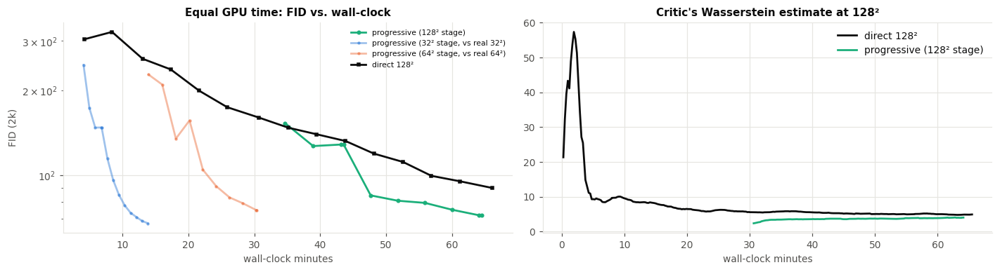

saved -> outputs\figures\fig23_ablation128_samples.png


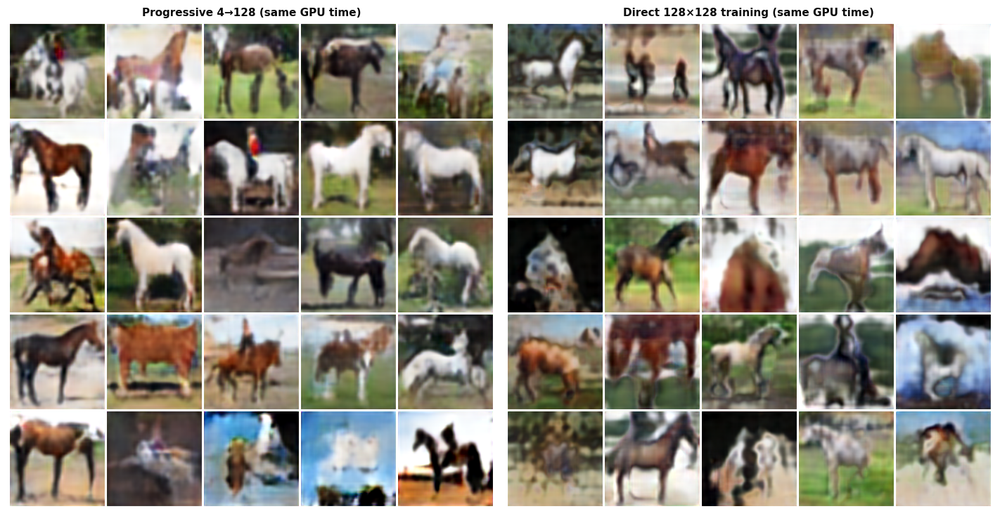

In [36]:
fd = pd.DataFrame(HIST_D128["fid"]); ld = pd.DataFrame(HIST_D128["log"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
fp = fidlog[fidlog.res == 128]
ax.plot(fp["time"] / 60, fp["fid"], "-o", ms=3, color=RES_COLOR[128], label="progressive (128² stage)")
for r in (32, 64):
    g = fidlog[fidlog.res == r]
    ax.plot(g["time"] / 60, g["fid"], "-o", ms=2, color=RES_COLOR[r], alpha=0.45, label=f"progressive ({r}² stage, vs real {r}²)")
ax.plot(fd["time"] / 60, fd["fid"], "-s", ms=3, color=INK, label="direct 128²")
ax.set_yscale("log"); ax.set_xlabel("wall-clock minutes"); ax.set_ylabel("FID (2k)")
ax.set_title("Equal GPU time: FID vs. wall-clock"); ax.legend(fontsize=7)
ax = axes[1]
ax.plot(ld["time"] / 60, sm(ld["w_dist"]), color=INK, label="direct 128²")
lp = log[log.res == 128]
ax.plot(lp["time"] / 60, sm(lp["w_dist"]), color=RES_COLOR[128], label="progressive (128² stage)")
ax.set_xlabel("wall-clock minutes"); ax.set_title("Critic's Wasserstein estimate at 128²"); ax.legend()
plt.tight_layout(); savefig(fig, "fig22_ablation128_curves.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 6.8))
axes[0].imshow(grid_image(SAMPLES[128][:25], 5, pad=3)); axes[0].set_title("Progressive 4→128 (same GPU time)")
axes[1].imshow(grid_image(S_d128[:25], 5, pad=3)); axes[1].set_title("Direct 128×128 training (same GPU time)")
for a in axes: a.axis("off")
plt.tight_layout(); savefig(fig, "fig23_ablation128_samples.png"); plt.show()

---
# 10. Summary of results and challenges encountered

In [37]:
summary = METRICS.loc[[32, 64, 128], ["FID-5k", "FID-5k raw G", "FID@32 (downsampled)", "KID×1e3", "precision",
                                      "recall", "horse rate", "test-1k FID (floor)"]].copy()
summary["train time (min)"] = [HIST["stage_time"][r] / 60 for r in summary.index]
summary["cumulative time (min)"] = [sum(HIST["stage_time"][q] for q in STAGES if q <= r) / 60 for r in summary.index]
display(summary.round(3))
summary.to_csv(RES / "summary.csv")
json.dump({"config": {k: (str(v) if isinstance(v, (dict, tuple)) else v) for k, v in asdict(CFG).items()},
           "metrics": METRICS.reset_index().to_dict(orient="records"),
           "classifier": CLS_DF.reset_index().to_dict(orient="records"),
           "classifier_test_acc": float(acc),
           "ablation": ABL.reset_index().to_dict(orient="records"),
           "ablation128": ABL128.reset_index().to_dict(orient="records"),
           "upsample_baseline": UPS_DF.to_dict(orient="records"),
           "memorisation": NN_DF.to_dict(orient="records"),
           "stage_time_s": {str(k): v for k, v in HIST["stage_time"].items()}},
          open(RES / "all_results.json", "w"), indent=1, default=float)
print("figures:", len(list(FIG.glob("*.png"))), "| results files:", len(list(RES.glob("*"))))

,FID-5k,FID-5k raw G,FID@32 (downsampled),KID×1e3,precision,recall,horse rate,test-1k FID (floor),train time (min),cumulative time (min)
res,,,,,,,,,,
32,61.177,71.510,61.177,48.739,0.457,0.225,0.755,24.335,10.659,13.885
64,69.983,77.921,49.162,57.361,0.479,0.156,0.804,24.192,16.496,30.381
128,66.715,74.039,45.466,50.891,0.443,0.171,0.841,25.294,34.086,64.466


figures: 25 | results files: 19


## 10.1 Results at a glance

| | 32 × 32 | 64 × 64 | 128 × 128 | real test set (floor) |
|---|---|---|---|---|
| FID-5k (EMA G) ↓ | **61.2** | 70.0 | 66.7 | – |
| FID-5k (raw G) ↓ | 71.5 | 77.9 | 74.0 | – |
| FID-1k ↓ | 76.6 | 86.3 | 83.9 | 24.2 – 25.3 |
| FID@32 (downsampled) ↓ | 61.2 | 49.2 | **45.5** | 24.3 |
| KID × 10³ ↓ | **48.7** | 57.4 | 50.9 | 0.03 – 0.07 |
| precision / recall ↑ | 0.457 / **0.225** | **0.479** / 0.156 | 0.443 / 0.171 | ≈ 0.72 / 0.70 |
| horse rate (CIFAR-10 classifier) ↑ | 75.5 % | 80.4 % | **84.1 %** | 94.0 % |
| stage training time | 10.7 min | 16.5 min | 34.1 min | – |

**What the numbers say.**

1. **The model produces recognisable horses at all three resolutions.** A ResNet-18 that reaches
   92.4 % on the CIFAR-10 test set labels 75–84 % of the generated images `horse`, against 94 % for
   real held-out horses. Most of the rest are labelled `deer` or `dog`, the classes whose
   shape is closest to a horse (§7.2).
2. **Growing kept improving the image *content*.** FID@32 (every sample box-downsampled to 32 × 32
   and compared with the native real images) falls 61.2 → 49.2 → 45.5, and the horse rate rises
   75.5 → 80.4 → 84.1 %. The low-resolution layers keep training while the new blocks are
   added, so the coarse structure goes on improving through the 64 and 128 stages.
3. **Native-resolution FID is not monotonic** (61.2 → 70.0 → 66.7). At 64 and 128 the comparison
   is against *bicubic-upsampled* reals, so the generator must also reproduce the exact smoothness of
   that filter, and every small high-frequency mismatch counts against it. The 128 stage was also still
   improving when its budget ran out (quick FID at its minimum on the very last checkpoint, §5.2).
4. **The 128 stage beats "generate at 32 and upsample"**: FID 66.7 vs. 85.4 and KID 50.9 vs. 68.6
   (§7.3). The extra blocks are not a no-op, even though the target holds no information beyond 32 × 32.
5. **Diversity is the weakest aspect.** Precision (≈ 0.45) is about 60 % of the real-data value, but
   recall (0.16–0.23) is only about 25–30 % of it. The generator covers the common modes (side-on
   brown/white horses on grass or sand, riders) and under-represents rarer ones (close-up heads,
   unusual backgrounds, jumping). This is partial mode dropping, not collapse: the
   minibatch-std layer and the visual grids show no repeated images.
6. **No memorisation.** Generated samples are *farther* from their nearest training image (median
   14.2 in Inception space) than the unseen real test horses are (11.3). The closest pairs share
   pose and colour but are clearly different images (§8.1).
7. **EMA matters.** Averaging the generator weights lowers FID by 7–10 points at every stage at
   zero training cost.
8. **No spectral artefacts.** Generated power spectra match the real ones to within ±0.05 in
   log₁₀ at all frequencies (§8.3), so there is no checkerboard or upsampling fingerprint.
   At 128 there is ≈ 5 % excess energy above the 32 × 32 Nyquist frequency: a little "invented" detail.

## 10.2 Progressive vs. direct training (§9)

| run | kimg | wall time | FID-5k ↓ | KID×10³ ↓ | precision | recall | horse rate |
|---|---|---|---|---|---|---|---|
| progressive 4 → 32 | 1 200 | 13.9 min | 61.2 | 48.7 | 0.457 | 0.225 | 75.5 % |
| direct 32 × 32 | 1 200 | 21.1 min | **47.5** | **31.1** | **0.489** | **0.250** | **79.9 %** |
| progressive 4 → 128 | 2 000 (400 at 128²) | 64.5 min | **66.7** | **50.9** | **0.443** | **0.171** | **84.1 %** |
| direct 128 × 128 | 750 | 66.1 min | 86.0 | 59.9 | 0.344 | 0.071 | 78.5 % |

**Reading the two ablations together.** At the native 32 × 32 resolution, growing does not pay off.
With the same 1 200 kimg, the directly trained network is better on every metric (FID 47.5 vs. 61.2),
because the progressive run spends half of those images in the 4–16 px stages, which only teach coarse
layout. At equal wall-clock time the two are roughly level: their FID-vs-time curves cross at ≈ 11 min
(Fig. 20).

**At the target resolution the result reverses.** With the same 64–66 minutes of GPU time, direct
128 × 128 training gets through only 750 kimg, every one at the full 128 × 128 cost. It ends at FID
86.0 and recall 0.071, against 66.7 and 0.171 for the progressive run, and the progressive run is
also ahead on KID, precision, FID@32 (45.5 vs. 56.9) and horse rate. The direct critic's Wasserstein
estimate spikes to ≈ 57 in the first minutes before settling. Its samples show the typical failure of
a deep network that must learn layout and texture at once: smeared bodies and extra or missing legs
(Fig. 23). The progressive run spends 47 % of its time below 128 × 128, where an image costs 5–28×
less, and reaches the 128 stage with the global structure already settled.

This matches ProGAN's claim: progressive growing buys **stability and speed at high resolution**. At
a small native resolution, where a plain WGAN-GP already trains well, it brings no benefit.

## 10.3 Challenges encountered

1. **No real data above 32 × 32.** CIFAR-10 is natively 32 × 32, so the "real" 64 and 128 images are
   bicubic upsamplings (§1.3). The 64 and 128 stages therefore learn to *imitate an interpolation
   filter*, not to add real detail. Every metric at those resolutions is measured against that
   filter, which is why the downsampled FID@32 is reported alongside them.
2. **Memory and speed of the gradient penalty.** The first implementation ran at **18 img/s at
   128 × 128 and needed 17.4 GB**, more than the 16 GB GPU, so it spilled into shared system memory.
   (batch 64). The WGAN-GP penalty differentiates through D twice and keeps a full double-backward graph.
   Three fixes together gave **≈ 200 img/s and 4–8 GB**: (i) equalised-LR scaling applied to the
   weights instead of the activations (saves one activation copy per layer); (ii) a *lazy* penalty
   every 4 steps on 32 samples with 4× weight; (iii) bfloat16 autocast with fp32 reductions.
3. **cuDNN autotuning stalled.** With `cudnn.benchmark = True` the first iterations hung for more
   than five minutes and used all 16 GB while trying algorithms for the double-backward convolutions on this
   Blackwell GPU. Benchmark mode is switched off.
4. **The critic gets stronger at every resolution.** The Wasserstein estimate grows
   0.96 → 1.53 → 3.80 (stabilisation means at 32/64/128) and the gradient penalty grows 0.009 → 0.038.
   The deeper discriminator separates the upsampled reals from the fakes more easily. Training still
   converged (FID kept falling), but this shows where to spend more budget: longer fade-ins
   or a lower learning rate at 128.
5. **Colour shock at each fade-in.** The fixed-latent timeline (§5.3) shows a global pink/magenta
   cast right after the 64 and 128 fade-ins begin, corrected within ≈ 100 kimg. The optimiser state is
   reset at each new stage (Adam's moment estimates restart from zero at lr = 10⁻³), and the new block's
   gradients flow back into the shared layers, so the first updates after a growth step are large.
   A short learning-rate warm-up after each growth step would probably remove it.
6. **Stale `toRGB` layers.** Evaluating the final generator with `alpha = 0` gives over-saturated
   images (§6.5), because a lower-resolution `toRGB` stops receiving gradients after its fade-in. The
   low-resolution outputs of a ProGAN cannot be reused once training has moved on; per-stage
   snapshots had to be saved to show them.
7. **Limited data.** 5 000 images (10 000 with flips) seen ≈ 400 times each risks discriminator
   over-fitting and memorisation. The nearest-neighbour test (§8.1) shows no memorisation, but the low
   recall indicates the generator has not covered the whole distribution. Differentiable
   augmentation (DiffAugment/ADA) is the standard remedy and the obvious next step.
8. **Evaluating with small samples.** FID is biased upward for small N (the real test set alone scores
   ≈ 24 at N = 1 000). All FIDs are therefore compared at equal N, a real-vs-real floor is reported, and
   KID (unbiased) is given alongside. Inception-v3 at 16 × 16 is barely meaningful, so the warm-up
   stages are judged visually.
9. **Engineering details.** Keeping the whole dataset on the GPU and building batches there avoided
   `DataLoader` workers (which break in Windows notebooks). Per-stage checkpoints let the
   notebook resume after an interrupted run, which happened once during this work. Floating-point
   accumulation of `kimg` (799.99 instead of 800) adds one extra quick-FID point at the start of some
   stabilisation phases; it is harmless but visible in the logs.

## 10.4 Possible improvements

* Longer schedules: every stage's FID was still falling at the end of its budget.
* DiffAugment or ADA to raise recall on the 5 000-image dataset.
* A learning-rate warm-up after each growth step to remove the colour shock.
* A super-resolution model (e.g. Real-ESRGAN) to create sharper 64/128 targets, so the high-resolution
  stages have real detail to learn. This changes the data distribution and would need to be reported as such.